# Analisis Longitudinal Playing Style Sepak Bola — FotMob

Notebook ini mengidentifikasi pola gaya bermain klub, mengevaluasi konsistensi hasil pengelompokan, lalu menganalisis dimensi gaya dan perubahannya antarmusim.

**Unit analisis:** clustering utama menggunakan satu baris per klub-musim (*club-season*). Analisis PCA-Varimax longitudinal menggunakan data klub-pertandingan agar skor gaya dapat dibentuk dengan skala global yang konsisten.

**Alur:** persiapan data → pembentukan dan seleksi fitur → clustering → evaluasi clustering → reliabilitas → PCA-Varimax dan analisis longitudinal → ekspor.

Jalankan seluruh sel dari atas secara berurutan. Di Colab, unggah dua CSV FotMob; secara lokal, letakkan keduanya di folder yang sama dengan notebook.

## 1. Upload dua dataset

**Penjelasan kode:** Memilih dan memuat dua file FotMob, yaitu data statistik klub per musim dan data statistik setiap pertandingan. Output memastikan kedua file ditemukan sebelum analisis dimulai.

**Output yang dihasilkan:** Menampilkan nama kedua file yang berhasil dibaca; jika salah satu file tidak tersedia, proses dihentikan dengan pesan kesalahan.

In [1]:
import os
try:
    from google.colab import files
    uploaded = files.upload()
    names = list(uploaded)
except ImportError:          # dijalankan lokal: baca file dari folder kerja
    names = os.listdir(".")

TEAM_FILE = next((n for n in names if n.startswith("fotmob_team_stats_wide_2021_2026")), None)
MATCH_FILE = next((n for n in names if n.startswith("fotmob_match_stats_wide_2021_2026")), None)
if TEAM_FILE is None or MATCH_FILE is None:
    raise FileNotFoundError(f"File tidak ditemukan. File yang tersedia: {names}")
print("Team dataset :", TEAM_FILE)
print("Match dataset:", MATCH_FILE)

Saving fotmob_match_stats_wide_2021_2026.csv to fotmob_match_stats_wide_2021_2026.csv
Saving fotmob_team_stats_wide_2021_2026.csv to fotmob_team_stats_wide_2021_2026.csv
Team dataset : fotmob_team_stats_wide_2021_2026.csv
Match dataset: fotmob_match_stats_wide_2021_2026.csv


## 2. Import library dan baca data

**Penjelasan kode:** Memanggil pustaka yang diperlukan untuk membaca data, membuat grafik, mengolah data, dan menjalankan analisis. Kedua dataset kemudian dimuat agar struktur dan contoh isinya bisa diperiksa.

**Output yang dihasilkan:** Menampilkan ukuran dataset klub (484 baris dan 35 kolom) serta dataset pertandingan (8.910 baris dan 106 kolom), disertai lima baris contoh dari masing-masing dataset.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

team = pd.read_csv(TEAM_FILE)
match = pd.read_csv(MATCH_FILE)

print("Team:", team.shape, "Match:", match.shape)
display(team.head())
display(match.head())

Team: (484, 35) Match: (8910, 106)


,league,season,team,team_id,_set_piece_goals_conceded_team,_set_piece_goals_team,_xg_diff_team,accurate_cross_team,accurate_long_balls_team,accurate_pass_team,...,phys_tdc_team,poss_won_att_3rd_team,possession_percentage_team,rating_team,saves_team,squad_value_team,total_red_card_team,total_tackle_team,total_yel_card_team,touches_in_opp_box_team
0,Bundesliga,2021/2022,1. FC Köln,8722,12.0,9.0,-1.0,6.1,30.3,342.7,...,NaN,5.7,55.1,6.92,3.2,NaN,1.0,17.6,66.0,812.0
1,Bundesliga,2021/2022,Arminia Bielefeld,9912,9.0,4.0,-37.4,3.0,28.6,255.7,...,NaN,4.4,40.4,6.66,3.8,NaN,2.0,16.1,53.0,591.0
2,Bundesliga,2021/2022,Augsburg,8406,8.0,9.0,-21.6,4.7,29.9,242.2,...,NaN,4.3,41.2,6.69,3.0,NaN,NaN,16.5,74.0,629.0
3,Bundesliga,2021/2022,Bayer Leverkusen,8178,14.0,11.0,18.8,4.1,27.1,404.9,...,NaN,3.3,53.8,7.06,3.4,NaN,2.0,14.2,64.0,855.0
4,Bundesliga,2021/2022,Bayern München,9823,4.0,18.0,53.3,5.3,31.1,559.7,...,NaN,7.6,64.8,7.29,2.2,NaN,2.0,16.6,36.0,1351.0


,fotmob_id,league_id,league,country_code,date_utc,home_team,away_team,home_goals,away_goals,date_local,...,away_corners,_fetch_status,home_physical_metrics_distance_covered,away_physical_metrics_distance_covered,home_physical_metrics_running,away_physical_metrics_running,home_physical_metrics_sprinting,away_physical_metrics_sprinting,home_physical_metrics_number_of_sprints,away_physical_metrics_number_of_sprints
0,3624340,54,Bundesliga,GER,2021-08-13 18:30:00+00:00,Borussia M'Gladbach,Bayern München,1,1,2021-08-13,...,8.0,success,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3624342,54,Bundesliga,GER,2021-08-14 13:30:00+00:00,Arminia Bielefeld,Freiburg,0,0,2021-08-14,...,9.0,success,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3624343,54,Bundesliga,GER,2021-08-14 13:30:00+00:00,Augsburg,TSG Hoffenheim,0,4,2021-08-14,...,5.0,success,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3624346,54,Bundesliga,GER,2021-08-14 13:30:00+00:00,Union Berlin,Bayer Leverkusen,1,1,2021-08-14,...,6.0,success,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3624345,54,Bundesliga,GER,2021-08-14 13:30:00+00:00,VfB Stuttgart,Greuther Fürth,5,1,2021-08-14,...,2.0,success,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Pembersihan: pertandingan yang muncul dua kali
Dalam satu musim liga round-robin ganda, pasangan (kandang, tandang) yang sama hanya boleh muncul **sekali**. Semua pasangan yang berulang ditampilkan, lalu keputusan dibuat **secara eksplisit per pertandingan** (bukan "ambil yang pertama menurut tanggal"), karena pilihan otomatis bisa salah: pada kasus Montpellier–Clermont, laga pertama menurut tanggal justru yang dihentikan.

**Penjelasan kode:** Memeriksa apakah ada pasangan tim kandang dan tandang yang tercatat lebih dari sekali pada liga dan musim yang sama. Pemeriksaan ini membantu menemukan pertandingan ganda atau pertandingan yang perlu dipastikan statusnya.

**Output yang dihasilkan:** Menampilkan pasangan pertandingan yang berulang agar dapat ditinjau sebelum data dibersihkan.

In [3]:
KEY_MATCH = ["league", "season", "home_team", "away_team"]
dup_all = match[match.duplicated(KEY_MATCH, keep=False)].sort_values(KEY_MATCH + ["date_local"])
print("Pasangan kandang-tandang yang muncul lebih dari sekali dalam satu liga-musim:")
display(dup_all[["fotmob_id", "league", "season", "date_local", "home_team", "away_team", "home_goals", "away_goals"]])

# Keputusan eksplisit per pertandingan (satu baris dibuang per pasangan)
DROP_MATCH_IDS = {
    4185671: "Serie A 2022/23, Spezia-Hellas Verona, 11 Jun 2023: tampaknya play-off degradasi, bukan laga liga reguler (belum diverifikasi)",
    4219326: "Ligue 1 2023/24, Montpellier-Clermont, 8 Okt 2023: berstatus abandoned; laga yang diselesaikan (29 Nov 2023) dipertahankan",
}
assert set(DROP_MATCH_IDS) <= set(dup_all["fotmob_id"]), "ID yang dibuang tidak ada di pasangan berulang"
assert len(dup_all) == 2 * len(DROP_MATCH_IDS), "Ada pasangan berulang baru yang belum diputuskan: periksa tabel di atas"

# Kolom statistik kedua baris Montpellier-Clermont: apakah identik selain gol dan tanggal?
pair = match.set_index("fotmob_id").loc[[4219326, 4356379]]
stat_cols = [c for c in pair.columns if c not in ("date_utc", "date_local", "home_goals", "away_goals")]
same = pair[stat_cols].iloc[0].fillna(-999).equals(pair[stat_cols].iloc[1].fillna(-999))
print("Kolom statistik baris 8 Okt dan 29 Nov identik (selain gol dan tanggal):", same)

for k, v in DROP_MATCH_IDS.items(): print(" dibuang", k, "->", v)
match = match[~match["fotmob_id"].isin(DROP_MATCH_IDS)].reset_index(drop=True)
print("Match setelah pembersihan:", match.shape)

Pasangan kandang-tandang yang muncul lebih dari sekali dalam satu liga-musim:


,fotmob_id,league,season,date_local,home_team,away_team,home_goals,away_goals
4259,4219326,Ligue 1,2023/24,2023-10-08,Montpellier,Clermont Foot,4,2
4305,4356379,Ligue 1,2023/24,2023-11-29,Montpellier,Clermont Foot,1,1
7633,3919287,Serie A,2022/23,2023-03-05,Spezia,Hellas Verona,0,0
7769,4185671,Serie A,2022/23,2023-06-11,Spezia,Hellas Verona,1,3


Kolom statistik baris 8 Okt dan 29 Nov identik (selain gol dan tanggal): True
 dibuang 4185671 -> Serie A 2022/23, Spezia-Hellas Verona, 11 Jun 2023: tampaknya play-off degradasi, bukan laga liga reguler (belum diverifikasi)
 dibuang 4219326 -> Ligue 1 2023/24, Montpellier-Clermont, 8 Okt 2023: berstatus abandoned; laga yang diselesaikan (29 Nov 2023) dipertahankan
Match setelah pembersihan: (8908, 106)


## 3. Pemeriksaan struktur, kunci, dan kualitas data

**Penjelasan kode:** Memeriksa kelengkapan data, baris yang berulang, dan kesesuaian identitas klub serta musim pada kedua dataset. Langkah ini membantu memastikan data yang dipakai tidak memiliki masalah struktur yang mengganggu analisis.

**Output yang dihasilkan:** Menampilkan jumlah data yang bermasalah dan kolom dengan nilai kosong terbanyak pada dataset klub maupun pertandingan.

In [4]:
KEY = ["league", "season", "team"]
for name, df in [("team", team), ("match", match)]:
    print(f"\n{name}:")
    print("Duplikat key club-season:", team.duplicated(KEY).sum() if name == "team" else "tidak berlaku pada level match")
    print("Missing terbanyak:")
    display(df.isna().sum().sort_values(ascending=False).head(15))

print("Duplikat club-season:", team.duplicated(KEY).sum())
print("Jumlah musim:", sorted(team["season"].dropna().astype(str).unique()))
print("Jumlah liga:", team["league"].nunique())


team:
Duplikat key club-season: 0
Missing terbanyak:


,0
phys_tdc_team,464
squad_value_team,330
total_red_card_team,28
penalty_won_team,5
penalty_conceded_team,3
league,0
season,0
team,0
team_id,0
_set_piece_goals_team,0



match:
Duplikat key club-season: tidak berlaku pada level match
Missing terbanyak:


,0
home_physical_metrics_number_of_sprints,8567
away_physical_metrics_number_of_sprints,8567
home_physical_metrics_distance_covered,8567
away_physical_metrics_distance_covered,8567
home_physical_metrics_running,8567
away_physical_metrics_running,8567
home_physical_metrics_sprinting,8567
away_physical_metrics_sprinting,8567
away_touches_opp_box,1134
home_touches_opp_box,1134


Duplikat club-season: 0
Jumlah musim: ['2021/2022', '2022/2023', '2023/2024', '2024/2025', '2025/2026']
Jumlah liga: 5


## 4. Bentuk tabel match-level panjang: satu baris per tim per pertandingan

**Penjelasan kode:** Mengubah data pertandingan agar setiap baris mewakili satu tim dalam satu pertandingan, baik saat bermain kandang maupun tandang. Dengan bentuk ini, statistik kedua tim dapat dianalisis menggunakan susunan kolom yang sama.

**Output yang dihasilkan:** Menghasilkan tabel panjang berisi 17.816 baris klub-pertandingan, sehingga satu pertandingan menghasilkan dua catatan tim.

In [5]:
# Ubah kolom home/away menjadi format team-match.
home_cols = [c for c in match.columns if c.startswith("home_")]
away_cols = [c for c in match.columns if c.startswith("away_")]

def make_side(side):
    prefix = side + "_"
    cols = [c for c in match.columns if c.startswith(prefix)]
    out = match[["fotmob_id", "league", "season", "date_local"] + cols].copy()
    out = out.rename(columns={c: c[len(prefix):] for c in cols})
    out["team"] = match["home_team"] if side == "home" else match["away_team"]
    out["opponent"] = match["away_team"] if side == "home" else match["home_team"]
    out["venue"] = side
    out["goals_for"] = match["home_goals"] if side == "home" else match["away_goals"]
    out["goals_against"] = match["away_goals"] if side == "home" else match["home_goals"]
    return out

home_long = make_side("home")
away_long = make_side("away")
match_long = pd.concat([home_long, away_long], ignore_index=True)

# Hindari menghitung pertandingan yang sama dua kali untuk satu klub.
match_long = match_long.drop_duplicates(["fotmob_id", "team"])
match_long["date_local"] = pd.to_datetime(match_long["date_local"], errors="coerce")
print("Rows team-match:", match_long.shape)
display(match_long[["league","season","team","opponent","venue","goals_for","goals_against"]].head())

Rows team-match: (17816, 57)


,league,season,team,opponent,venue,goals_for,goals_against
0,Bundesliga,2021/22,Borussia M'Gladbach,Bayern München,home,1,1
1,Bundesliga,2021/22,Arminia Bielefeld,Freiburg,home,0,0
2,Bundesliga,2021/22,Augsburg,TSG Hoffenheim,home,0,4
3,Bundesliga,2021/22,Union Berlin,Bayer Leverkusen,home,1,1
4,Bundesliga,2021/22,VfB Stuttgart,Greuther Fürth,home,5,1


## 5. Hitung jumlah penampilan aktual per club-season dari data pertandingan

**Penjelasan kode:** Menyamakan penulisan nama klub dan musim, lalu menghitung jumlah pertandingan yang benar-benar dimainkan setiap klub dari data pertandingan. Hasil hitungan ini dipakai untuk memeriksa apakah ringkasan statistik per musim sudah sesuai.

**Output yang dihasilkan:** Menampilkan jumlah klub-musim yang berhasil dicocokkan serta sebaran jumlah pertandingan tiap klub.

In [6]:
# ==========================================
# NORMALISASI MUSIM DAN NAMA KLUB
# ==========================================

def normalize_season(season):
    season = str(season).strip()
    parts = season.split("/")

    if len(parts) == 2:
        return f"{parts[0]}/{parts[1][-2:]}"

    return season


def normalize_team(name):
    name = str(name).lower().strip()

    replacements = {
        "ü": "u",
        "ö": "o",
        "ä": "a",
        "é": "e",
        "è": "e",
        "á": "a",
        "í": "i",
        "'": "",
        ".": "",
        "-": " "
    }

    for old, new in replacements.items():
        name = name.replace(old, new)

    return " ".join(name.split())


# Alias nama klub: nama alternatif -> nama standar
TEAM_ALIASES = {
    # Bundesliga
    "bayern munchen": "bayern munich",
    "borussia mgladbach": "borussia monchengladbach",
    "borussia monchengladbach": "borussia monchengladbach",
    "fc augsburg": "augsburg",
    "sc freiburg": "freiburg",
    "vfl bochum": "bochum",
    "sv darmstadt": "darmstadt",
    "tsg hoffenheim": "hoffenheim",
    "fc koln": "1 fc koln",

    # La Liga
    "athletic bilbao": "athletic club",

    # Premier League
    "bournemouth": "afc bournemouth",
    "brighton": "brighton & hove albion",
    "wolverhampton": "wolverhampton wanderers",

    # Ligue 1
    "saint etienne": "saint etienne",

    # Serie A
    "ac milan": "milan",
    "ssc napoli": "napoli",
    "parma calcio 1913": "parma",
    "verona": "hellas verona"
}


def canonical_team(name):
    normalized = normalize_team(name)
    return TEAM_ALIASES.get(normalized, normalized)


# Terapkan normalisasi ke kedua dataset
team["season_norm"] = team["season"].apply(normalize_season)
match_long["season_norm"] = match_long["season"].apply(normalize_season)

team["team_norm"] = team["team"].apply(canonical_team)
match_long["team_norm"] = match_long["team"].apply(canonical_team)


# ==========================================
# HITUNG JUMLAH PERTANDINGAN
# ==========================================

appearances = (
    match_long.groupby(
        ["league", "season_norm", "team_norm"],
        dropna=False
    )
    .agg(
        matches_from_match=("fotmob_id", "nunique")
    )
    .reset_index()
)


# Pastikan tidak ada duplikasi key pada hasil agregasi
assert not appearances.duplicated(
    ["league", "season_norm", "team_norm"]
).any()


# Merge ulang dari awal
team = team.drop(
    columns=["matches_from_match"],
    errors="ignore"
)

team = team.merge(
    appearances,
    on=["league", "season_norm", "team_norm"],
    how="left",
    validate="one_to_one"
)


# ==========================================
# HASIL PEMERIKSAAN
# ==========================================

print("Jumlah club-season:", len(team))
print("Berhasil dicocokkan:", team["matches_from_match"].notna().sum())
print("Belum cocok:", team["matches_from_match"].isna().sum())

print("\nDistribusi jumlah pertandingan:")
display(
    team.groupby(["league", "season"])["matches_from_match"]
    .agg(["min", "max", "mean"])
    .round(2)
)

print("\nKlub yang belum cocok:")
display(
    team.loc[
        team["matches_from_match"].isna(),
        ["league", "season", "team"]
    ]
)
# Tahun awal musim diekstrak dari empat digit pertama, misalnya 2021/2022 -> 2021.
team["season_start"] = pd.to_numeric(team["season"].astype(str).str.extract(r"(20\d{2})")[0], errors="coerce")


Jumlah club-season: 484
Berhasil dicocokkan: 484
Belum cocok: 0

Distribusi jumlah pertandingan:


min  max  mean
league         season                   
Bundesliga     2021/2022   34   34  34.0
               2022/2023   34   34  34.0
               2023/2024   34   34  34.0
               2024/2025   34   34  34.0
               2025/2026   34   34  34.0
La Liga        2021/2022   38   38  38.0
               2022/2023   38   38  38.0
               2023/2024   38   38  38.0
               2024/2025   38   38  38.0
               2025/2026   38   38  38.0
Ligue 1        2021/2022   38   38  38.0
               2022/2023   38   38  38.0
               2023/2024   34   34  34.0
               2024/2025   34   34  34.0
               2025/2026   34   34  34.0
Premier League 2021/2022   38   38  38.0
               2022/2023   38   38  38.0
               2023/2024   38   38  38.0
               2024/2025   38   38  38.0
               2025/2026   38   38  38.0
Serie A        2021/2022   38   38  38.0
               2022/2023   38   38  38.0
               2023/2024   38   38  38.0
               2024/2025   38   38  38.0
               2025/2026   38   38  38.0


Klub yang belum cocok:


,league,season,team


**Penjelasan kode:** Memeriksa apakah ada klub-musim dengan jumlah pertandingan yang tidak wajar dibandingkan rentang yang diharapkan. Tujuannya memastikan tidak ada klub yang terlewat atau memiliki catatan pertandingan yang tidak lengkap.

**Output yang dihasilkan:** Menampilkan jumlah anomali dan daftar klub-musim yang perlu diperiksa; hasil kosong berarti tidak ditemukan anomali berdasarkan batas pemeriksaan ini.

In [7]:
# Periksa jumlah pertandingan yang tidak sesuai
anomalies = team[
    (team["matches_from_match"] < 30) |
    (team["matches_from_match"] > 38)
][
    ["league", "season", "team", "matches_from_match"]
].sort_values(
    ["league", "season", "matches_from_match"]
)

print("Jumlah anomali:", len(anomalies))
display(anomalies)

Jumlah anomali: 0


,league,season,team,matches_from_match


## 6. Rekonsiliasi cakupan team-season dan match-season

**Penjelasan kode:** Mencocokkan daftar klub-musim pada dataset statistik klub dengan daftar yang dibentuk dari data pertandingan. Langkah ini memastikan kedua sumber mencakup klub dan musim yang sama.

**Output yang dihasilkan:** Menampilkan hasil pencocokan, termasuk data yang cocok dan data yang hanya muncul pada salah satu dataset.

In [8]:
# Rekonsiliasi cakupan memakai key yang sudah dinormalisasi pada Cell 10.
TEAM_MATCH_KEY = ["league", "season_norm", "team_norm"]

team_keys = team[TEAM_MATCH_KEY].drop_duplicates()
match_keys = appearances[TEAM_MATCH_KEY].drop_duplicates()
coverage = team_keys.merge(match_keys, on=TEAM_MATCH_KEY, how="outer", indicator=True)

print("Status pencocokan key club-season:")
display(coverage["_merge"].value_counts())
display(coverage[coverage["_merge"] != "both"].head(20))

# Jumlah klub per liga-musim; perbedaan dapat disebabkan promosi/degradasi,
# cakupan endpoint, atau data yang tidak terkumpul.
club_counts = team.groupby(["league", "season"])["team"].nunique().unstack()
display(club_counts)

Status pencocokan key club-season:


,count
_merge,
both,484
left_only,0
right_only,0


,league,season_norm,team_norm,_merge


season,2021/2022,2022/2023,2023/2024,2024/2025,2025/2026
league,,,,,
Bundesliga,18,18,18,18,18
La Liga,20,20,20,20,20
Ligue 1,20,20,18,18,18
Premier League,20,20,20,20,20
Serie A,20,20,20,20,20


**Penjelasan kode:** Merangkum jumlah pertandingan yang berhasil dihitung untuk setiap klub-musim setelah kedua dataset dicocokkan. Ringkasan ini menjadi pemeriksaan akhir sebelum memilih dan membentuk fitur analisis.

**Output yang dihasilkan:** Menampilkan statistik jumlah pertandingan, seperti nilai minimum, maksimum, rata-rata, serta klub-musim yang tidak memiliki jumlah pertandingan valid.

In [9]:
# Ringkasan jumlah penampilan setelah rekonsiliasi team-season dan match-season.
print("Jumlah penampilan dari data pertandingan:")
display(team["matches_from_match"].describe())

print("Club-season tanpa jumlah penampilan valid:", int(
    (team["matches_from_match"].isna() | (team["matches_from_match"] <= 0)).sum()
))

print("Missing values pada dataset team-season:")
display(team.isna().sum().sort_values(ascending=False).head(15))

Jumlah penampilan dari data pertandingan:


,matches_from_match
count,484.000000
mean,36.809917
std,1.830562
min,34.000000
25%,34.000000
50%,38.000000
75%,38.000000
max,38.000000


Club-season tanpa jumlah penampilan valid: 0
Missing values pada dataset team-season:


,0
phys_tdc_team,464
squad_value_team,330
total_red_card_team,28
penalty_won_team,5
penalty_conceded_team,3
season,0
league,0
_xg_diff_team,0
_set_piece_goals_team,0
_set_piece_goals_conceded_team,0


## 7. Feature engineering dan perlakuan satuan

Audit empiris (sel di bawah) menunjukkan sebagian statistik team-season sudah berupa rerata per pertandingan, sebagian lain total musiman. Hanya total musiman yang dibagi jumlah pertandingan.

**Fitur yang dikeluarkan dari klaster dan alasannya:**
- `goals_team_match`, `goals_conceded_team_match`: **hasil pertandingan**, bukan gaya. Jika dimasukkan, klaster ikut mengelompokkan tim menurut hasil, dan membandingkan klaster dengan gol menjadi sirkuler.
- `saves_team`: ditentukan oleh jumlah tembakan lawan, bukan pilihan gaya tim itu sendiri.
- `total_red_card_team`: sangat jarang, 28 nilai hilang, dan noise tinggi.
- Fitur kontekstual (nilai skuad, rating, kehadiran, phys_tdc) dikeluarkan seperti sebelumnya.

Kolom-kolom itu tetap ada di tabel dan dipakai **setelah** klasterisasi sebagai pembanding.

Klasifikasi per-match vs total berdasarkan audit empiris. Jika definisi resmi FotMob berbeda, catat sebagai keterbatasan.

**Penjelasan kode:** Membentuk kandidat fitur gaya bermain dengan memperhatikan apakah suatu statistik sudah berupa rata-rata per pertandingan atau masih berupa jumlah total. Penyesuaian ini mencegah statistik dibagi dua kali atau dibandingkan dalam satuan yang berbeda.

**Output yang dihasilkan:** Menampilkan perlakuan satuan untuk setiap fitur dan daftar fitur kandidat yang akan diperiksa lebih lanjut.

In [10]:
# FEATURE ENGINEERING : perlakuan unit berdasarkan audit team-season vs match-level.
# Statistik yang sudah berupa rerata per pertandingan TIDAK dibagi lagi.
# Statistik yang berupa total musiman dikonversi menjadi per pertandingan.
# Metrik yang tidak memiliki padanan/definisi yang cukup jelas tidak dimasukkan ke model utama.

MATCH_RATES = [
    "accurate_cross_team", "accurate_long_balls_team", "accurate_pass_team",
    "effective_clearance_team", "fk_foul_lost_team", "interception_team",
    "ontarget_scoring_att_team", "total_tackle_team"
]

SEASON_TOTALS = [
    "big_chance_missed_team", "big_chance_team", "corner_taken_team",
    "expected_goals_team", "total_yel_card_team",
    "touches_in_opp_box_team"
]

# Metrik rate/mean yang dipertahankan dalam unit aslinya.
RATE_FEATURES = ["possession_percentage_team"]

# Dikeluarkan dari fitur klaster (tetap dipakai SETELAH klasterisasi sebagai pembanding)
EXCLUDED_REASON = {
    "goals_team_match": "hasil pertandingan, bukan gaya",
    "goals_conceded_team_match": "hasil pertandingan, bukan gaya",
    "saves_team": "ditentukan oleh tembakan lawan, bukan pilihan gaya",
    "total_red_card_team": "sangat jarang; 28 nilai hilang; noise tinggi",
}

# Metrik kontekstual/identitas dikeluarkan dari clustering.
ID_COLUMNS = [
    "league", "season", "team", "team_id", "season_norm",
    "team_norm", "season_start", "matches_from_match"
]
CONTEXT_EXCLUDE = [
    "squad_value_team", "rating_team", "home_attendance_team",
    "phys_tdc_team"
]

team["matches_from_match"] = pd.to_numeric(
    team["matches_from_match"], errors="coerce"
)
valid_matches = team["matches_from_match"].where(
    team["matches_from_match"] > 0
)

available_totals = [c for c in SEASON_TOTALS if c in team.columns]
available_rates = [
    c for c in MATCH_RATES + RATE_FEATURES if c in team.columns
]

for col in available_totals:
    team[col] = pd.to_numeric(team[col], errors="coerce")
    team[col + "_per_match"] = team[col] / valid_matches

candidate_features = available_rates + [
    c + "_per_match" for c in available_totals
]
candidate_features = list(dict.fromkeys(
    c for c in candidate_features if c in team.columns
))

feature_audit = pd.DataFrame({
    "unit_treatment": [
        "already_per_match_or_rate" if c in available_rates
        else "season_total_divided_by_matches"
        for c in candidate_features
    ],
    "missing_n": team[candidate_features].isna().sum(),
    "missing_pct": (team[candidate_features].isna().mean() * 100).round(2),
    "unique_values": team[candidate_features].nunique(dropna=True),
    "mean": team[candidate_features].mean(),
    "std": team[candidate_features].std()
})
feature_audit.index.name = "feature"
display(feature_audit)

candidate_features = [
    c for c in candidate_features
    if team[c].isna().mean() <= 0.20
    and team[c].nunique(dropna=True) > 1
]
print("Kandidat fitur :", candidate_features)
print("Dikeluarkan karena alasan konsep:", EXCLUDED_REASON)
print("Dikecualikan dari clustering:",
      [c for c in ID_COLUMNS + CONTEXT_EXCLUDE if c in team.columns])


,unit_treatment,missing_n,missing_pct,unique_values,mean,std
feature,,,,,,
accurate_cross_team,already_per_match_or_rate,0,0.0,44,4.312810,0.783606
accurate_long_balls_team,already_per_match_or_rate,0,0.0,150,24.694215,3.806321
accurate_pass_team,already_per_match_or_rate,0,0.0,446,366.424174,86.520417
effective_clearance_team,already_per_match_or_rate,0,0.0,177,20.233058,4.809159
fk_foul_lost_team,already_per_match_or_rate,0,0.0,78,11.920868,1.594400
interception_team,already_per_match_or_rate,0,0.0,70,8.769628,1.425778
ontarget_scoring_att_team,already_per_match_or_rate,0,0.0,49,4.388430,0.981585
total_tackle_team,already_per_match_or_rate,0,0.0,79,16.334298,1.683700
possession_percentage_team,already_per_match_or_rate,0,0.0,208,50.001653,6.578971


Kandidat fitur : ['accurate_cross_team', 'accurate_long_balls_team', 'accurate_pass_team', 'effective_clearance_team', 'fk_foul_lost_team', 'interception_team', 'ontarget_scoring_att_team', 'total_tackle_team', 'possession_percentage_team', 'big_chance_missed_team_per_match', 'big_chance_team_per_match', 'corner_taken_team_per_match', 'expected_goals_team_per_match', 'total_yel_card_team_per_match', 'touches_in_opp_box_team_per_match']
Dikeluarkan karena alasan konsep: {'goals_team_match': 'hasil pertandingan, bukan gaya', 'goals_conceded_team_match': 'hasil pertandingan, bukan gaya', 'saves_team': 'ditentukan oleh tembakan lawan, bukan pilihan gaya', 'total_red_card_team': 'sangat jarang; 28 nilai hilang; noise tinggi'}
Dikecualikan dari clustering: ['league', 'season', 'team', 'team_id', 'season_norm', 'team_norm', 'season_start', 'matches_from_match', 'squad_value_team', 'rating_team', 'home_attendance_team', 'phys_tdc_team']


**Penjelasan kode:** Membandingkan statistik agregat klub dengan rata-rata statistik dari catatan pertandingan untuk memeriksa satuan dan konsistensi nilainya. Hasil perbandingan membantu menentukan apakah suatu kolom perlu dinormalisasi berdasarkan jumlah penampilan.

**Output yang dihasilkan:** Menampilkan pasangan fitur yang dibandingkan beserta rasio nilainya sebagai dasar pemeriksaan satuan.

In [11]:
# AUDIT UNIT V6: bandingkan nilai team-season dengan rerata match-level.
# Rasio sekitar 1: nilai team-season kemungkinan sudah per pertandingan.
# Rasio sekitar jumlah pertandingan: nilai team-season kemungkinan total musiman.
# Audit ini merupakan pemeriksaan empiris; definisi sumber tetap perlu dicantumkan.

TEAM_TO_MATCH_METRIC = {
    "accurate_cross_team": "accurate_crosses",
    "accurate_long_balls_team": "long_balls_accurate",
    "accurate_pass_team": "accurate_passes",
    "big_chance_missed_team": "big_chance_missed_title",
    "big_chance_team": "big_chance",
    "corner_taken_team": "corners",
    "effective_clearance_team": "clearances",
    "fk_foul_lost_team": "fouls",
    "interception_team": "interceptions",
    "ontarget_scoring_att_team": "shotsontarget",
    "saves_team": "keeper_saves",
    "total_red_card_team": "red_cards",
    "total_tackle_team": "matchstats_headers_tackles",
    "total_yel_card_team": "yellow_cards",
    "touches_in_opp_box_team": "touches_opp_box",
    "expected_goals_team": "expected_goals",
}

match_metric_cols = [
    m for m in TEAM_TO_MATCH_METRIC.values() if m in match_long.columns
]
match_means = (
    match_long.groupby(["league", "season_norm", "team_norm"])[match_metric_cols]
    .mean(numeric_only=True).reset_index()
)

unit_rows = []
for team_col, match_col in TEAM_TO_MATCH_METRIC.items():
    if team_col not in team.columns or match_col not in match_means.columns:
        continue
    temp = team[
        ["league", "season_norm", "team_norm", "matches_from_match", team_col]
    ].merge(
        match_means[
            ["league", "season_norm", "team_norm", match_col]
        ],
        on=["league", "season_norm", "team_norm"], how="inner"
    )
    temp[team_col] = pd.to_numeric(temp[team_col], errors="coerce")
    temp[match_col] = pd.to_numeric(temp[match_col], errors="coerce")
    temp["ratio_to_match_mean"] = (
        temp[team_col] / temp[match_col].replace(0, np.nan)
    )
    unit_rows.append({
        "team_feature": team_col,
        "match_feature": match_col,
        "matched_club_seasons": len(temp),
        "median_team_value": temp[team_col].median(),
        "median_match_mean": temp[match_col].median(),
        "median_ratio": temp["ratio_to_match_mean"].median(),
        "median_matches": temp["matches_from_match"].median(),
        "corr_team_vs_match_mean":
            temp[[team_col, match_col]].corr().iloc[0, 1]
    })

unit_audit = pd.DataFrame(unit_rows)
display(unit_audit.round(3))
unit_audit.to_csv("fotmob_metric_unit_audit_v9.csv", index=False)


,team_feature,match_feature,matched_club_seasons,median_team_value,median_match_mean,median_ratio,median_matches,corr_team_vs_match_mean
0,accurate_cross_team,accurate_crosses,484,4.30,4.250,1.001,38.0,0.999
1,accurate_long_balls_team,long_balls_accurate,484,24.30,24.303,1.000,38.0,1.000
2,accurate_pass_team,accurate_passes,484,353.35,353.332,1.000,38.0,1.000
3,big_chance_missed_team,big_chance_missed_title,484,46.00,1.250,38.000,38.0,0.986
4,big_chance_team,big_chance,484,76.00,2.079,38.000,38.0,0.985
5,corner_taken_team,corners,484,174.00,4.737,38.000,38.0,0.962
6,effective_clearance_team,clearances,484,19.80,19.813,1.000,38.0,1.000
7,fk_foul_lost_team,fouls,484,12.00,11.974,1.000,38.0,1.000
8,interception_team,interceptions,484,8.60,8.625,1.000,38.0,1.000
9,ontarget_scoring_att_team,shotsontarget,484,4.20,4.211,1.000,38.0,1.000


## 8. Audit distribusi dan korelasi fitur

**Penjelasan kode:** Melihat ringkasan nilai dan pola hubungan antarfitur kandidat sebelum fitur dipilih. Pemeriksaan ini membantu menemukan fitur yang memiliki rentang nilai tidak biasa atau hubungan yang sangat kuat dengan fitur lain.

**Output yang dihasilkan:** Menghasilkan tabel statistik deskriptif dan peta korelasi antarfitur kandidat.

,count,mean,std,min,25%,50%,75%,max
accurate_cross_team,484.0,4.312810,0.783606,2.300000,3.800000,4.300000,4.800000,6.900000
accurate_long_balls_team,484.0,24.694215,3.806321,15.400000,22.075000,24.300000,27.100000,39.400000
accurate_pass_team,484.0,366.424174,86.520417,198.400000,302.975000,353.350000,413.425000,659.700000
effective_clearance_team,484.0,20.233058,4.809159,9.700000,16.800000,19.800000,23.100000,35.600000
fk_foul_lost_team,484.0,11.920868,1.594400,7.600000,10.700000,12.000000,13.000000,17.100000
interception_team,484.0,8.769628,1.425778,5.700000,7.800000,8.600000,9.600000,13.300000
ontarget_scoring_att_team,484.0,4.388430,0.981585,2.300000,3.700000,4.200000,4.900000,8.500000
total_tackle_team,484.0,16.334298,1.683700,11.600000,15.200000,16.200000,17.500000,22.100000
possession_percentage_team,484.0,50.001653,6.578971,35.100000,44.700000,49.500000,54.100000,69.100000
big_chance_missed_team_per_match,484.0,1.319058,0.430259,0.447368,1.000000,1.250000,1.588235,3.382353


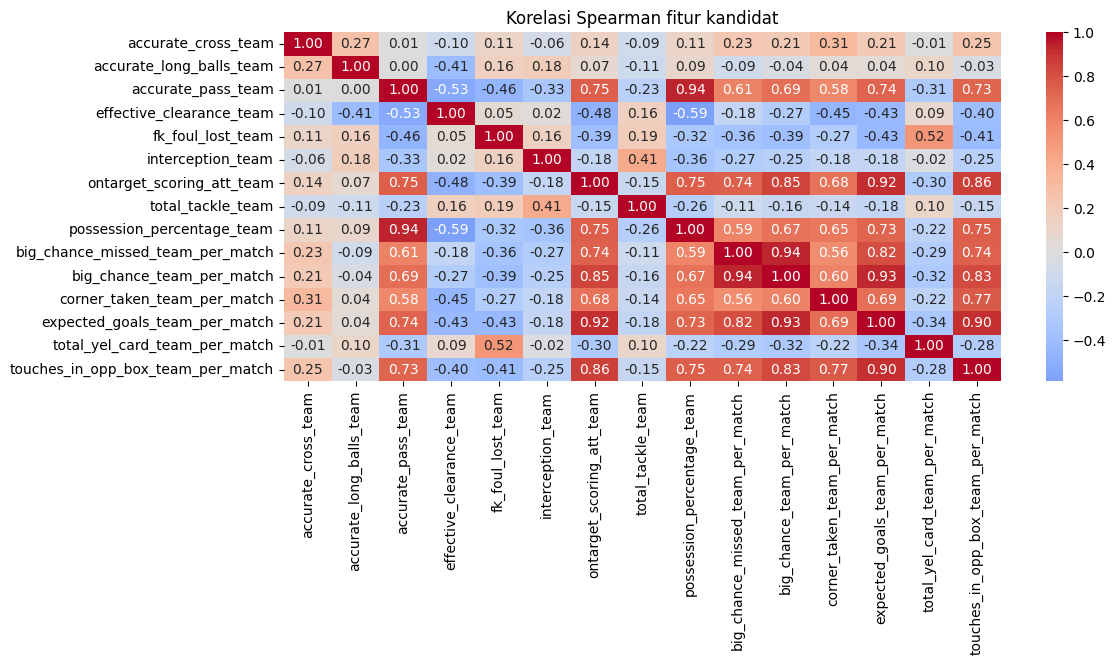

In [12]:
display(team[candidate_features].describe().T)
plt.figure(figsize=(12, max(5, len(candidate_features)*0.45)))
sns.heatmap(team[candidate_features].corr(method="spearman"), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Korelasi Spearman fitur kandidat")
plt.tight_layout()
plt.show()

## 9. Seleksi fitur eksplisit dan pemeriksaan redundansi

Pasangan dengan |Spearman ρ| ≥ 0,85 dicatat, lalu **satu fitur dari tiap pasangan dibuang secara eksplisit dengan alasan tertulis** (bukan otomatis). Tujuannya mencegah satu aspek (mis. volume serangan) dihitung berkali-kali dan mendominasi jarak antar-klub.

**Penjelasan kode:** Memeriksa fitur yang memiliki hubungan sangat kuat, lalu mengurangi fitur yang terlalu mirip agar informasi yang sama tidak terlalu mendominasi analisis. Pemilihan akhir dilakukan secara eksplisit supaya alasan setiap fitur dipakai atau dibuang dapat ditelusuri.

**Output yang dihasilkan:** Menampilkan pasangan fitur dengan korelasi tinggi serta daftar fitur yang dipertahankan untuk analisis berikutnya.

In [13]:
SELECTED_FEATURES = candidate_features.copy()
corr = team[SELECTED_FEATURES].corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
def high_pairs(cols, thr=0.85):
    c = team[cols].corr(method="spearman").abs()
    u = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
    return [(a, b, float(u.loc[a, b])) for a in u.index for b in u.columns if pd.notna(u.loc[a, b]) and u.loc[a, b] >= thr]

print("Pasangan |rho| >= 0.85 SEBELUM seleksi:")
for a, b, rho in high_pairs(SELECTED_FEATURES): print(f"  {a} <-> {b}: {rho:.3f}")

# Keputusan eksplisit + alasan
DROP_FEATURES = {
    "accurate_pass_team": "ρ=0,94 dengan penguasaan bola; penguasaan bola dipertahankan sebagai ukuran tunggal",
    "ontarget_scoring_att_team": "redundan dengan volume peluang dan sentuhan di kotak penalti",
    "big_chance_missed_team_per_match": "ρ=0,94 dengan big chance (dan sebagian hasil penyelesaian)",
    "expected_goals_team_per_match": "ρ≥0,90 dengan big chance dan sentuhan di kotak; juga dipakai sebagai ukuran kekuatan (xG diff), jadi tidak dimasukkan sebagai fitur",
}
SELECTED_FEATURES = [c for c in SELECTED_FEATURES if c not in DROP_FEATURES]
print("\nDibuang:"); [print(f"  {k}: {v}") for k, v in DROP_FEATURES.items()]
print("\nPasangan |rho| >= 0.85 SETELAH seleksi:", high_pairs(SELECTED_FEATURES) or "tidak ada")
print("\nFitur aktif (%d):" % len(SELECTED_FEATURES), SELECTED_FEATURES)
assert len(SELECTED_FEATURES) >= 2

Pasangan |rho| >= 0.85 SEBELUM seleksi:
  accurate_pass_team <-> possession_percentage_team: 0.941
  ontarget_scoring_att_team <-> expected_goals_team_per_match: 0.915
  ontarget_scoring_att_team <-> touches_in_opp_box_team_per_match: 0.863
  big_chance_missed_team_per_match <-> big_chance_team_per_match: 0.937
  big_chance_team_per_match <-> expected_goals_team_per_match: 0.926
  expected_goals_team_per_match <-> touches_in_opp_box_team_per_match: 0.903

Dibuang:
  accurate_pass_team: ρ=0,94 dengan penguasaan bola; penguasaan bola dipertahankan sebagai ukuran tunggal
  ontarget_scoring_att_team: redundan dengan volume peluang dan sentuhan di kotak penalti
  big_chance_missed_team_per_match: ρ=0,94 dengan big chance (dan sebagian hasil penyelesaian)
  expected_goals_team_per_match: ρ≥0,90 dengan big chance dan sentuhan di kotak; juga dipakai sebagai ukuran kekuatan (xG diff), jadi tidak dimasukkan sebagai fitur

Pasangan |rho| >= 0.85 SETELAH seleksi: tidak ada

Fitur aktif (11): ['acc

## 10. Siapkan matriks clustering

Pilihan standardisasi dan koreksi kekuatan untuk clustering klub-musim:
- `STANDARDIZATION = "pooled"`: z-score atas seluruh klub-musim; mempertahankan perbedaan antarliga dan pergeseran antarmusim.
- `STANDARDIZATION = "within_league_season"`: z-score dalam tiap liga-musim; mengukur posisi relatif klub terhadap klub lain pada liga-musim yang sama dan menghapus perbedaan rata-rata antarkelompok tersebut.
- `ADJUST_STRENGTH = True`: tiap fitur diregresikan pada selisih xG per laga, lalu residunya dipakai. Ini koreksi statistik, bukan bukti bahwa gaya sepenuhnya bebas dari kualitas tim; ada risiko *over-control* karena gaya juga dapat memengaruhi kekuatan.

Keempat konfigurasi standardisasi × koreksi kekuatan dibandingkan pada bagian sensitivitas. Pilihan final harus dibaca bersama metrik internal, ukuran cluster, stabilitas, dan interpretabilitas.

**Penjelasan kode:** Menyiapkan data klub-musim untuk proses pengelompokan dengan mengisi nilai kosong, menyamakan skala fitur, dan menentukan apakah perbedaan kekuatan tim perlu dikoreksi. Pengaturan pada bagian ini menentukan dasar perbandingan antarklub.

**Output yang dihasilkan:** Menampilkan jumlah nilai yang diisi, pilihan standardisasi dan koreksi kekuatan, serta ukuran matriks yang siap digunakan untuk clustering.

In [14]:
STANDARDIZATION = "within_league_season"     # "pooled" atau "within_league_season"
ADJUST_STRENGTH = False       # True: koreksi kekuatan tim (selisih xG per laga)

# _xg_diff_team adalah total musiman (mis. +53,3 untuk Bayern 2021/22) -> per pertandingan
team["xg_diff_per_match"] = pd.to_numeric(team["_xg_diff_team"], errors="coerce") / team["matches_from_match"]

GROUP = ["league", "season_norm"]

def zscore_frame(df, by=None):
    if by is None:
        return (df - df.mean()) / df.std(ddof=0)
    g = df.groupby([team[c] for c in by])
    return (df - g.transform("mean")) / g.transform(lambda s: s.std(ddof=0))

def build_matrix(standardization, adjust_strength, verbose=False):
    X_raw = team[SELECTED_FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    all_missing = X_raw.columns[X_raw.isna().all()].tolist()
    if all_missing:
        raise ValueError(f"Fitur seluruhnya missing: {all_missing}")
    if verbose:
        print("Nilai yang diimputasi (median):", int(X_raw.isna().sum().sum()))
    X_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_raw), columns=X_raw.columns, index=team.index)
    Z = zscore_frame(X_imp, GROUP if standardization == "within_league_season" else None)
    if adjust_strength:
        s = zscore_frame(team[["xg_diff_per_match"]], GROUP if standardization == "within_league_season" else None).iloc[:, 0]
        A = np.column_stack([np.ones(len(s)), s.values])
        R = Z.copy()
        for c in Z.columns:
            b = np.linalg.lstsq(A, Z[c].values, rcond=None)[0]
            R[c] = Z[c].values - A @ b
        Z = (R - R.mean()) / R.std(ddof=0)
    return Z

X_df = build_matrix(STANDARDIZATION, ADJUST_STRENGTH, verbose=True)
X = X_df.values
print("Standardisasi:", STANDARDIZATION, "| koreksi kekuatan:", ADJUST_STRENGTH)
print("Shape matriks clustering:", X.shape, "| missing:", int(np.isnan(X).sum()))
print("Fitur:", SELECTED_FEATURES)

Nilai yang diimputasi (median): 0
Standardisasi: within_league_season | koreksi kekuatan: False
Shape matriks clustering: (484, 11) | missing: 0
Fitur: ['accurate_cross_team', 'accurate_long_balls_team', 'effective_clearance_team', 'fk_foul_lost_team', 'interception_team', 'total_tackle_team', 'possession_percentage_team', 'big_chance_team_per_match', 'corner_taken_team_per_match', 'total_yel_card_team_per_match', 'touches_in_opp_box_team_per_match']


## 11. Bandingkan jumlah cluster (k)

Gunakan metrik internal sebagai alat bantu, bukan penentu tunggal. Silhouette yang rendah menunjukkan pemisahan cluster lemah. Keputusan k final juga mempertimbangkan ukuran cluster, profil fitur, stabilitas subsampling, dan kemudahan interpretasi.

**Penjelasan kode:** Menguji beberapa jumlah kelompok pada K-Means untuk melihat berapa banyak kelompok yang paling masuk akal berdasarkan ukuran evaluasi. Nilai metrik digunakan sebagai bahan pertimbangan, bukan satu-satunya penentu jumlah kelompok.

**Output yang dihasilkan:** Menampilkan tabel nilai evaluasi untuk setiap jumlah kelompok dan grafik perbandingannya.

,algorithm,k,silhouette,davies_bouldin,calinski_harabasz,inertia
0,KMeans,2,0.293111,1.332695,215.728337,3677.889893
1,KMeans,3,0.184447,1.728178,154.032545,3245.415406
2,KMeans,4,0.142526,1.901020,125.909566,2979.403634
3,KMeans,5,0.131930,1.865698,109.482422,2781.233974
5,KMeans,7,0.130618,1.776031,89.153535,2509.630174
4,KMeans,6,0.128806,1.812567,98.895177,2616.899852
6,KMeans,8,0.125168,1.849493,82.159151,2410.988593


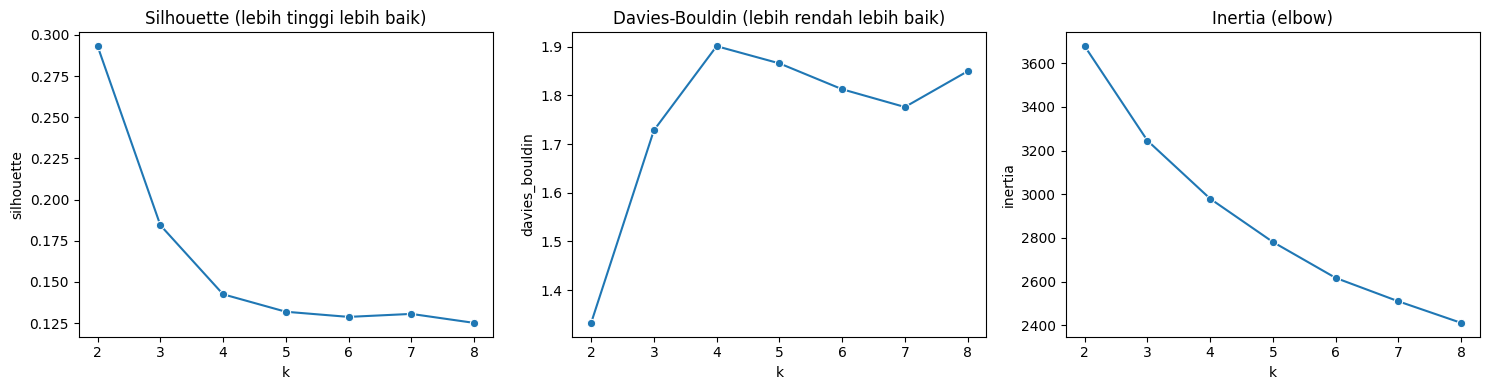

In [15]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=30)
    labels = km.fit_predict(X)
    rows.append({
        "algorithm": "KMeans", "k": k,
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "inertia": km.inertia_
    })

metrics = pd.DataFrame(rows)
display(metrics.sort_values("silhouette", ascending=False))
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.lineplot(data=metrics, x="k", y="silhouette", marker="o", ax=axes[0])
sns.lineplot(data=metrics, x="k", y="davies_bouldin", marker="o", ax=axes[1])
sns.lineplot(data=metrics, x="k", y="inertia", marker="o", ax=axes[2])
axes[0].set_title("Silhouette (lebih tinggi lebih baik)")
axes[1].set_title("Davies-Bouldin (lebih rendah lebih baik)")
axes[2].set_title("Inertia (elbow)")
plt.tight_layout()
plt.show()

## 12. Perbandingan algoritma pada beberapa nilai k

## 12. Perbandingan algoritma pada beberapa nilai k
K-means dan hierarki Ward dibandingkan karena keduanya dipakai dalam literatur yang ditinjau. Spectral clustering dihapus (tidak ada dalam literatur tersebut dan tidak memberi informasi tambahan di sini). Kolom `ARI_vs_KMeans` menunjukkan seberapa mirip pembagian Ward dengan K-means.

**Penjelasan kode:** Membandingkan beberapa metode pengelompokan dan jumlah kelompok untuk melihat apakah pola hasilnya konsisten. Perbandingan ini membantu menentukan metode yang paling sesuai dengan bentuk data.

**Output yang dihasilkan:** Menampilkan nilai evaluasi tiap metode, termasuk kualitas pemisahan kelompok dan kesamaan hasil antar metode.

In [16]:
comparison = []
for k in range(2, 7):
    km_lab = KMeans(n_clusters=k, random_state=42, n_init=30).fit_predict(X)
    wd_lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    for name, lab in [("KMeans", km_lab), ("Ward", wd_lab)]:
        comparison.append({
            "algorithm": name, "k": k,
            "silhouette": silhouette_score(X, lab),
            "davies_bouldin": davies_bouldin_score(X, lab),
            "calinski_harabasz": calinski_harabasz_score(X, lab),
            "ARI_vs_KMeans": adjusted_rand_score(km_lab, lab),
        })
comparison = pd.DataFrame(comparison)
display(comparison.sort_values(["k", "algorithm"]).round(3))

,algorithm,k,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_KMeans
0,KMeans,2,0.293,1.333,215.728,1.000
1,Ward,2,0.200,1.702,152.776,0.393
2,KMeans,3,0.184,1.728,154.033,1.000
3,Ward,3,0.153,1.890,126.618,0.517
4,KMeans,4,0.143,1.901,125.910,1.000
5,Ward,4,0.129,1.911,101.106,0.286
6,KMeans,5,0.132,1.866,109.482,1.000
7,Ward,5,0.088,2.174,87.690,0.282
8,KMeans,6,0.129,1.813,98.895,1.000
9,Ward,6,0.065,2.195,77.144,0.283


## 13. Tetapkan model final berdasarkan evaluasi + interpretabilitas

`FINAL_K` ditetapkan setelah membaca tabel evaluasi, profil, dan stabilitas pada data yang sedang dijalankan. Jangan memakai angka v8 sebagai justifikasi . Jika k=2 memiliki metrik internal lebih baik, k=3 hanya boleh dipilih bila memberi profil tambahan yang konsisten dan berguna secara substantif. Jika silhouette rendah, sebut hasil sebagai kecenderungan/profil dalam kontinum, bukan kelompok taktik yang terpisah tegas.

**Penjelasan kode:** Menetapkan model dan jumlah kelompok setelah mempertimbangkan hasil evaluasi, ukuran kelompok, serta kemudahan menjelaskan karakteristiknya. Pilihan ini menjadi model utama untuk analisis lanjutan.

**Output yang dihasilkan:** Menampilkan metode dan jumlah kelompok terpilih, nilai evaluasi, serta banyaknya klub-musim pada setiap kelompok.

In [17]:
# Tentukan model setelah membaca tabel evaluasi dan profil cluster.
# Jangan mengunci k hanya dari silhouette tertinggi.
FINAL_ALGORITHM = "KMeans"  # KMeans / Agglomerative
FINAL_K = 3   # dapat diubah; lihat sel sensitivitas dan stabilitas per k di bawah

if FINAL_K < 2:
    raise ValueError("FINAL_K minimal 2.")
if FINAL_ALGORITHM == "KMeans":
    final_model = KMeans(n_clusters=FINAL_K, random_state=42, n_init=50)
    labels = final_model.fit_predict(X)
elif FINAL_ALGORITHM == "Agglomerative":
    final_model = AgglomerativeClustering(n_clusters=FINAL_K, linkage="ward")
    labels = final_model.fit_predict(X)
else:
    raise ValueError("Algoritma tidak dikenal")

team["cluster"] = labels
print("Model:", FINAL_ALGORITHM, "| k:", FINAL_K)
print("Silhouette:", silhouette_score(X, labels))
print("Davies-Bouldin:", davies_bouldin_score(X, labels))
print("Ukuran cluster:")
display(team["cluster"].value_counts().sort_index())


Model: KMeans | k: 3
Silhouette: 0.18444667686885777
Davies-Bouldin: 1.7281777855703184
Ukuran cluster:


,count
cluster,
0,250
1,176
2,58


## 14. Visualisasi PCA

**Penjelasan kode:** Meringkas data ke dalam dua dimensi agar hasil pengelompokan lebih mudah dilihat. Setiap titik mewakili satu klub-musim dan warnanya menunjukkan kelompok yang diperoleh.

**Output yang dihasilkan:** Menghasilkan grafik sebaran dua dimensi serta persentase informasi data yang dapat dijelaskan oleh kedua dimensi tersebut.

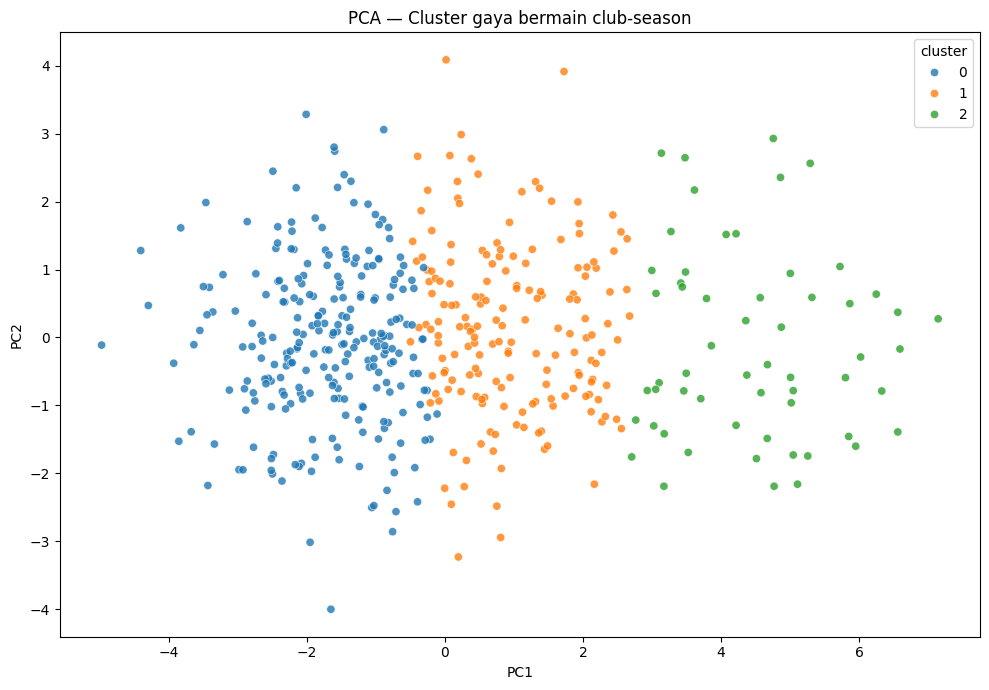

Explained variance ratio: [0.46326715 0.14018173] total: 0.6034488798969567


In [18]:
pca = PCA(n_components=2, random_state=42)
xy = pca.fit_transform(X)
plot_df = team[[*KEY, "cluster"]].copy()
plot_df["PC1"], plot_df["PC2"] = xy[:,0], xy[:,1]
plt.figure(figsize=(10,7))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="cluster", palette="tab10", alpha=.8)
plt.title("PCA — Cluster gaya bermain club-season")
plt.tight_layout()
plt.show()
print("Explained variance ratio:", pca.explained_variance_ratio_, "total:", pca.explained_variance_ratio_.sum())

## 15. Profil cluster dalam satuan asli

**Penjelasan kode:** Menghitung nilai rata-rata fitur asli pada setiap kelompok agar ciri khas masing-masing kelompok dapat dibandingkan. Dengan demikian, kelompok tidak hanya terlihat berbeda pada grafik, tetapi juga dapat dijelaskan melalui statistik sepak bola.

**Output yang dihasilkan:** Menampilkan tabel rata-rata fitur untuk setiap kelompok beserta jumlah klub-musim di dalamnya.

In [19]:
profile = team.groupby("cluster")[SELECTED_FEATURES].mean().round(3)
profile["n"] = team.groupby("cluster").size()
display(profile)

,accurate_cross_team,accurate_long_balls_team,effective_clearance_team,fk_foul_lost_team,interception_team,total_tackle_team,possession_percentage_team,big_chance_team_per_match,corner_taken_team_per_match,total_yel_card_team_per_match,touches_in_opp_box_team_per_match,n
cluster,,,,,,,,,,,,
0,4.156,24.413,22.612,12.396,9.196,16.751,45.262,1.754,4.329,2.083,19.397,250
1,4.430,24.644,18.720,11.780,8.591,16.199,53.053,2.437,5.125,1.977,24.941,176
2,4.633,26.057,14.571,10.302,7.471,14.948,61.171,3.246,6.156,1.619,32.956,58


## 16. Distribusi cluster menurut liga dan musim

**Penjelasan kode:** Melihat bagaimana anggota kelompok tersebar menurut musim dan liga. Pemeriksaan ini membantu mengetahui apakah kelompok tertentu hanya didominasi liga atau musim tertentu.

**Output yang dihasilkan:** Menampilkan persentase komposisi kelompok per musim dan per liga.

cluster,0,1,2
season,,,
2021/2022,53.1,34.7,12.2
2022/2023,51.0,36.7,12.2
2023/2024,50.0,38.5,11.5
2024/2025,52.1,35.4,12.5
2025/2026,52.1,36.5,11.5


cluster,0,1,2
league,,,
Bundesliga,55.6,34.4,10.0
La Liga,51.0,37.0,12.0
Ligue 1,50.0,41.5,8.5
Premier League,53.0,32.0,15.0
Serie A,49.0,37.0,14.0


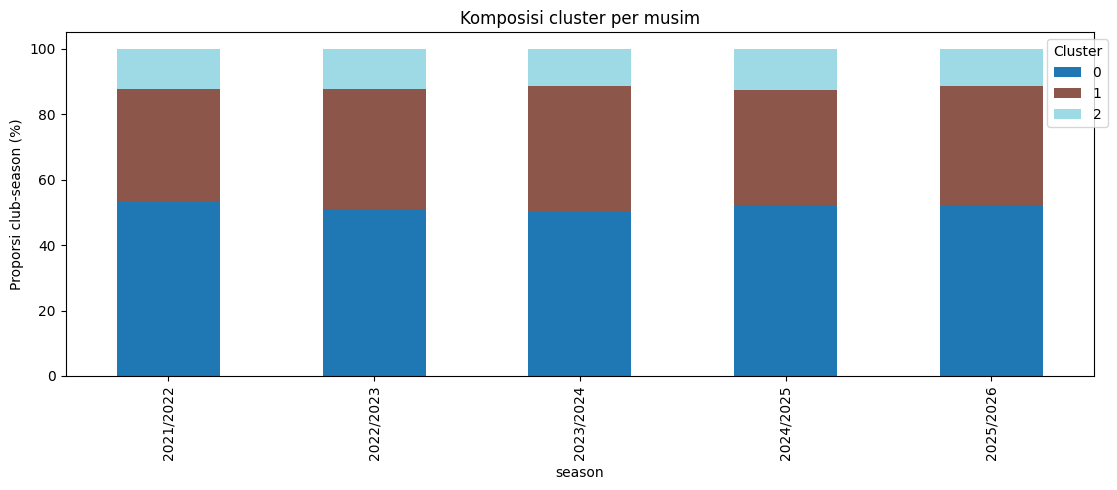

In [20]:
season_dist = pd.crosstab(team["season"], team["cluster"], normalize="index") * 100
league_dist = pd.crosstab(team["league"], team["cluster"], normalize="index") * 100
display(season_dist.round(1))
display(league_dist.round(1))

season_dist.plot(kind="bar", stacked=True, figsize=(12,5), colormap="tab20")
plt.ylabel("Proporsi club-season (%)")
plt.title("Komposisi cluster per musim")
plt.legend(title="Cluster", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

**Penjelasan kode:** Membandingkan komposisi kelompok ketika menggunakan dua cara penyamaan skala data. Tujuannya melihat apakah pola kelompok berubah ketika perbedaan antar liga-musim dipertahankan atau disetarakan.

**Output yang dihasilkan:** Menampilkan perbandingan proporsi kelompok dari kedua pengaturan standardisasi.

In [21]:
# Komposisi klaster per musim di bawah dua standardisasi (konfigurasi lain sama).
# Pada "within_league_season" proporsi tiap klaster per liga-musim cenderung tetap karena rata-rata liga-musim dihapus;
# perbedaan dengan "pooled" menunjukkan seberapa besar pergeseran antarmusim memengaruhi hasil.
rows = {}
for std in ["pooled", "within_league_season"]:
    Xc = build_matrix(std, ADJUST_STRENGTH).values
    lab_c = KMeans(n_clusters=FINAL_K, random_state=42, n_init=50).fit_predict(Xc)
    ct = pd.crosstab(team["season"], lab_c, normalize="index") * 100
    # beri nama klaster menurut rata-rata penguasaan bola agar sebanding antar konfigurasi
    order = pd.Series(team["possession_percentage_team"].values).groupby(lab_c).mean().sort_values().index
    ct = ct[list(order)]; ct.columns = [f"klaster_{i+1}(poss naik)" for i in range(len(order))]
    rows[std] = ct.round(1)
display(pd.concat(rows, axis=1))

pooled                                            \
          klaster_1(poss naik) klaster_2(poss naik) klaster_3(poss naik)   
season                                                                     
2021/2022                 15.3                 63.3                 21.4   
2022/2023                 19.4                 58.2                 22.4   
2023/2024                 30.2                 40.6                 29.2   
2024/2025                 54.2                 15.6                 30.2   
2025/2026                 62.5                  9.4                 28.1   

          within_league_season                                            
          klaster_1(poss naik) klaster_2(poss naik) klaster_3(poss naik)  
season                                                                    
2021/2022                 53.1                 34.7                 12.2  
2022/2023                 51.0                 36.7                 12.2  
2023/2024                 50.0                 38.5                 11.5  
2024/2025                 52.1                 35.4                 12.5  
2025/2026                 52.1                 36.5                 11.5

## 17. Analisis transisi antar-musim (club-level)

**Penjelasan kode:** Mengikuti klub yang sama dari satu musim ke musim berikutnya, lalu mencatat apakah klub tersebut tetap berada di kelompok yang sama atau berpindah. Hanya klub yang dapat dicocokkan pada dua musim berurutan dalam liga yang sama yang dibandingkan.

**Output yang dihasilkan:** Menampilkan jumlah klub yang cocok dan tabel perpindahan kelompok untuk setiap pasangan musim.

In [22]:
# Identitas klub + musim untuk analisis longitudinal.
# season_start dibuat dengan regex raw-string agar backslash tidak ter-escape keliru.
team["team_key"] = team["team"].apply(canonical_team)
team["season_start"] = pd.to_numeric(
    team["season"].astype(str).str.extract(r"(20\d{2})")[0],
    errors="coerce"
)
if team["season_start"].isna().any():
    raise ValueError("Ada season yang gagal diekstrak; periksa format kolom season.")

transition_rows = []
seasons = (
    team[["season", "season_start"]].drop_duplicates()
    .sort_values("season_start")["season"].tolist()
)
for s1, s2 in zip(seasons[:-1], seasons[1:]):
    a = team[team["season"] == s1][
        ["league", "team_key", "team", "cluster"]
    ].drop_duplicates(["league", "team_key"])
    b = team[team["season"] == s2][
        ["league", "team_key", "team", "cluster"]
    ].drop_duplicates(["league", "team_key"])
    joined = a.merge(
        b, on=["league", "team_key"], suffixes=("_from", "_to"),
        validate="one_to_one"
    )
    if len(joined):
        transition_rows.append((s1, s2, joined))
        print(f"{s1} -> {s2}: {len(joined)} klub cocok dalam liga yang sama")
        display(pd.crosstab(
            joined["cluster_from"], joined["cluster_to"], normalize="index"
        ).round(3))


2021/2022 -> 2022/2023: 84 klub cocok dalam liga yang sama


cluster_to,0,1,2
cluster_from,,,
0,0.816,0.184,0.000
1,0.206,0.706,0.088
2,0.000,0.250,0.750


2022/2023 -> 2023/2024: 83 klub cocok dalam liga yang sama


cluster_to,0,1,2
cluster_from,,,
0,0.829,0.171,0.000
1,0.194,0.750,0.056
2,0.000,0.250,0.750


2023/2024 -> 2024/2025: 82 klub cocok dalam liga yang sama


cluster_to,0,1,2
cluster_from,,,
0,0.833,0.167,0.000
1,0.200,0.714,0.086
2,0.000,0.182,0.818


2024/2025 -> 2025/2026: 82 klub cocok dalam liga yang sama


cluster_to,0,1,2
cluster_from,,,
0,0.806,0.194,0.000
1,0.265,0.676,0.059
2,0.000,0.250,0.750


### Pembanding untuk tabel transisi
Angka "bertahan 86%" tidak bermakna tanpa pembanding. Di bawah ini dihitung **kesepakatan yang diharapkan jika klaster musim berikutnya tidak berhubungan dengan klaster musim sebelumnya** (dari proporsi marginal), serta Cohen's kappa. Pembanding ini belum memisahkan noise pengukuran dari perubahan gaya sebenarnya, jadi kappa adalah batas bawah stabilitas, bukan estimasi perubahan murni.

**Penjelasan kode:** Membandingkan perpindahan kelompok yang benar-benar terjadi dengan perpindahan yang mungkin muncul secara kebetulan. Pembanding ini membantu menilai apakah klub cenderung mempertahankan kelompoknya lebih sering daripada perkiraan acak.

**Output yang dihasilkan:** Menampilkan tingkat klub yang bertahan, perkiraan bertahan secara acak, dan nilai kappa sebagai ukuran kesepakatan.

In [23]:
rows = []
for s1, s2, joined in transition_rows:
    obs = float((joined["cluster_from"] == joined["cluster_to"]).mean())
    pf = joined["cluster_from"].value_counts(normalize=True)
    pt = joined["cluster_to"].value_counts(normalize=True)
    exp = float(sum(pf.get(c, 0) * pt.get(c, 0) for c in set(pf.index) | set(pt.index)))
    rows.append({"dari": s1, "ke": s2, "n_klub": len(joined), "bertahan_diamati": obs,
                 "bertahan_diharapkan_acak": exp, "kappa": (obs - exp) / (1 - exp)})
trans_summary = pd.DataFrame(rows)
display(trans_summary.round(3))
print("Rata-rata: diamati %.3f | acak %.3f | kappa %.3f" % (trans_summary.bertahan_diamati.mean(), trans_summary.bertahan_diharapkan_acak.mean(), trans_summary.kappa.mean()))

,dari,ke,n_klub,bertahan_diamati,bertahan_diharapkan_acak,kappa
0,2021/2022,2022/2023,84,0.762,0.389,0.610
1,2022/2023,2023/2024,83,0.783,0.390,0.644
2,2023/2024,2024/2025,82,0.780,0.390,0.640
3,2024/2025,2025/2026,82,0.744,0.390,0.580


Rata-rata: diamati 0.767 | acak 0.390 | kappa 0.619


## 18. Stabilitas cluster melalui subsampling

**Penjelasan kode:** Menguji kestabilan hasil clustering dengan mengambil sebagian data berulang kali dan menjalankan pengelompokan kembali. Hasilnya dibandingkan untuk melihat apakah klub cenderung tetap berada dalam kelompok yang sama.

**Output yang dihasilkan:** Menampilkan rata-rata dan sebaran nilai ARI; nilai yang lebih tinggi menunjukkan hasil pengelompokan lebih konsisten pada pengujian ini.

In [24]:
# Refit KMeans pada subsample dan bandingkan label untuk observasi yang sama.
# ARI tidak terpengaruh oleh nomor label cluster yang tertukar.
from sklearn.utils import resample

stability_scores = []
if FINAL_ALGORITHM == "KMeans":
    base_labels = labels
    rng = np.random.default_rng(42)
    for rep in range(30):
        idx = np.sort(rng.choice(len(X), size=int(0.80*len(X)), replace=False))
        model_rep = KMeans(n_clusters=FINAL_K, random_state=rep, n_init=20)
        rep_labels = model_rep.fit_predict(X[idx])
        stability_scores.append(adjusted_rand_score(base_labels[idx], rep_labels))
    print("Mean ARI:", np.mean(stability_scores))
    print("Std ARI:", np.std(stability_scores))
    display(pd.Series(stability_scores, name="ARI subsample").describe())
else:
    print("Stability subsampling pada notebook ini dijalankan untuk KMeans; model final bukan KMeans.")

Mean ARI: 0.9223925571418928
Std ARI: 0.08660423783941786


,ARI subsample
count,30.000000
mean,0.922393
std,0.088085
min,0.557349
25%,0.898404
50%,0.944713
75%,0.981247
max,1.000000


**Penjelasan kode:** Menguji kestabilan untuk beberapa pilihan jumlah kelompok, bukan hanya model yang dipilih. Langkah ini membantu melihat apakah penambahan kelompok membuat hasil semakin tidak stabil.

**Output yang dihasilkan:** Menampilkan perbandingan nilai silhouette dan kestabilan ARI untuk setiap jumlah kelompok.

In [25]:
# Stabilitas subsampel untuk beberapa k (80% data, 30 ulangan). ARI tinggi pada k kecil sering hanya menunjukkan bahwa
# pembelahan kasar sebuah kontinum itu stabil, bukan bahwa kelompoknya nyata; baca bersama silhouette.
rows = []
rng = np.random.default_rng(42)
for k in range(2, 6):
    base = KMeans(n_clusters=k, random_state=42, n_init=30).fit_predict(X)
    sc = []
    for rep in range(30):
        idx = np.sort(rng.choice(len(X), size=int(0.80 * len(X)), replace=False))
        lab_r = KMeans(n_clusters=k, random_state=rep, n_init=20).fit_predict(X[idx])
        sc.append(adjusted_rand_score(base[idx], lab_r))
    rows.append({"k": k, "silhouette": silhouette_score(X, base), "ARI_mean": np.mean(sc), "ARI_sd": np.std(sc)})
display(pd.DataFrame(rows).set_index("k").round(3))

,silhouette,ARI_mean,ARI_sd
k,,,
2,0.293,0.985,0.021
3,0.184,0.914,0.122
4,0.143,0.666,0.210
5,0.132,0.663,0.154


### Sensitivitas: standardisasi dan koreksi kekuatan
Silhouette K-means untuk empat konfigurasi. Silhouette yang rendah di semua konfigurasi berarti data lebih mirip kontinum daripada kelompok terpisah.

**Penjelasan kode:** Menguji apakah hasil pengelompokan berubah ketika cara penyamaan skala dan koreksi kekuatan tim diganti. Ini membantu mengetahui seberapa peka hasil analisis terhadap pilihan pengolahan data.

**Output yang dihasilkan:** Menampilkan nilai silhouette dari beberapa kombinasi pengaturan sebagai bahan perbandingan.

In [26]:
rows = []
for std in ["pooled", "within_league_season"]:
    for adj in [False, True]:
        Xc = build_matrix(std, adj).values
        for k in range(2, 6):
            lab_c = KMeans(n_clusters=k, random_state=42, n_init=30).fit_predict(Xc)
            rows.append({"standardisasi": std, "koreksi_kekuatan": adj, "k": k, "silhouette": silhouette_score(Xc, lab_c)})
display(pd.DataFrame(rows).pivot_table(index=["standardisasi", "koreksi_kekuatan"], columns="k", values="silhouette").round(3))

k                                          2      3      4      5
standardisasi        koreksi_kekuatan                            
pooled               False             0.238  0.150  0.135  0.139
                     True              0.134  0.119  0.120  0.113
within_league_season False             0.293  0.184  0.143  0.132
                     True              0.144  0.122  0.103  0.097

## 19. Validasi pendukung menggunakan data pertandingan

**Penjelasan kode:** Merangkum kembali statistik dari data pertandingan untuk setiap klub-musim, kemudian menghubungkannya dengan kelompok yang sudah terbentuk. Data pertandingan ini digunakan sebagai pemeriksaan pendukung terhadap profil kelompok.

**Output yang dihasilkan:** Menampilkan jumlah klub-musim yang berhasil dicocokkan dan ringkasan statistik pertandingan berdasarkan kelompok.

In [27]:
# Ringkasan match-level per club-season.
# Gunakan key ternormalisasi karena format season/nama klub dapat berbeda
# antara file team-season dan file pertandingan.
match_metrics = [
    "total_shots", "shotsontarget", "expected_goals", "passes",
    "accurate_passes_pct", "long_balls_accurate_pct", "accurate_crosses",
    "touches_opp_box", "interceptions", "clearances", "ballpossesion",
    "fouls", "corners"
]
available_match_metrics = [c for c in match_metrics if c in match_long.columns]

if not available_match_metrics:
    raise ValueError("Tidak ada kolom metrik pertandingan yang cocok untuk validasi.")

match_summary = (
    match_long.groupby(TEAM_MATCH_KEY)[available_match_metrics]
    .mean(numeric_only=True)
    .reset_index()
)

validation = team[
    list(dict.fromkeys(TEAM_MATCH_KEY + ["season", "team", "cluster"]))
].merge(
    match_summary,
    on=TEAM_MATCH_KEY,
    how="left"
)

print("Club-season dengan ringkasan match-level:", validation[available_match_metrics].notna().any(axis=1).sum())
print("Club-season tanpa ringkasan match-level:", validation[available_match_metrics].isna().all(axis=1).sum())
display(validation.groupby("cluster")[available_match_metrics].mean().round(3))

# Catatan: metrik match-level ini hanya validasi pendukung, bukan fitur clustering.

Club-season dengan ringkasan match-level: 484
Club-season tanpa ringkasan match-level: 0


,total_shots,shotsontarget,expected_goals,passes,accurate_passes_pct,long_balls_accurate_pct,accurate_crosses,touches_opp_box,interceptions,clearances,ballpossesion,fouls,corners
cluster,,,,,,,,,,,,,
0,11.363,3.776,1.158,390.593,77.503,43.807,4.156,19.444,9.199,22.610,45.260,12.395,4.327
1,13.249,4.725,1.520,478.974,82.670,49.156,4.427,24.846,8.593,18.723,53.055,11.779,5.125
2,16.253,6.008,1.990,590.170,87.253,57.261,4.635,33.008,7.462,14.572,61.161,10.301,6.156


## 20. Hubungkan klaster dengan outcome (bukan fitur klaster)
Gol, gol kebobolan, dan penyelamatan kiper **tidak** dipakai membentuk klaster pada v7, sehingga perbandingan ini tidak lagi sirkuler untuk kolom tersebut. Selisih xG dipakai sebagai ukuran kekuatan (dan sebagai koreksi bila `ADJUST_STRENGTH=True`).

**Penjelasan kode:** Menghubungkan kelompok yang terbentuk dengan hasil pertandingan seperti gol, kebobolan, selisih xG, dan rating. Variabel hasil ini dipakai untuk membantu memahami kelompok, bukan untuk membentuk kelompok sejak awal.

**Output yang dihasilkan:** Menampilkan ringkasan hasil pertandingan per kelompok dan memeriksa apakah variabel outcome ikut digunakan sebagai fitur clustering.

In [28]:
# Outcome digunakan untuk interpretasi pasca-clustering, bukan membentuk cluster.
outcome_cols = [c for c in [
    "goals_team_match", "goals_conceded_team_match", "xg_diff_per_match",
    "expected_goals_team", "expected_goals_conceded_team", "rating_team",
    "squad_value_team"
] if c in team.columns]

print("Kolom outcome yang juga menjadi fitur klaster:", [c for c in outcome_cols if c in SELECTED_FEATURES] or "tidak ada")
if outcome_cols:
    display(team.groupby("cluster")[outcome_cols].mean().round(3))
else:
    print("Kolom outcome tidak ditemukan.")

Kolom outcome yang juga menjadi fitur klaster: tidak ada


,goals_team_match,goals_conceded_team_match,xg_diff_per_match,expected_goals_team,expected_goals_conceded_team,rating_team,squad_value_team
cluster,,,,,,,
0,1.130,1.600,-0.388,42.494,56.720,6.742,1.736168e+08
1,1.554,1.273,0.243,55.724,46.872,6.922,3.606967e+08
2,2.171,1.002,0.935,73.564,39.112,7.148,8.921617e+08


**Penjelasan kode:** Menguji apakah hasil pertandingan berbeda di antara kelompok yang terbentuk. Pengujian ini membantu melihat hubungan antara karakteristik gaya bermain dan hasil yang dicapai klub.

**Output yang dihasilkan:** Menampilkan ringkasan uji statistik untuk setiap variabel hasil, termasuk jumlah data dan nilai pengujian.

In [29]:
import numpy as np
import pandas as pd
from itertools import combinations
from scipy import stats
from statsmodels.stats.multitest import multipletests

TEST_VARS = [c for c in [
    "xg_diff_per_match", "goals_team_match", "goals_conceded_team_match",
    "squad_value_team", "rating_team"
] if c in team.columns]

overlap = set(TEST_VARS) & set(SELECTED_FEATURES)
assert not overlap, f"Variabel uji tidak boleh fitur klaster: {overlap}"
print("Variabel uji:", TEST_VARS)

clusters = sorted(team["cluster"].unique())
omni_rows, pair_rows = [], []

for v in TEST_VARS:
    d = team[["cluster", v]].copy()
    d[v] = pd.to_numeric(d[v], errors="coerce")
    d = d.dropna()
    groups = {k: d.loc[d["cluster"] == k, v].values for k in clusters}
    arr = [g for g in groups.values() if len(g) > 1]
    n = len(d)

    # Pemeriksaan asumsi
    p_shapiro_min = min(stats.shapiro(g)[1] for g in arr if len(g) >= 3)
    p_levene = stats.levene(*arr, center="median")[1]

    # ANOVA satu arah + eta kuadrat
    F, p_anova = stats.f_oneway(*arr)
    grand = d[v].mean()
    eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in arr) / ((d[v] - grand) ** 2).sum()

    # Kruskal-Wallis + epsilon kuadrat
    H, p_kw = stats.kruskal(*arr)
    eps2 = H / (n - 1)

    omni_rows.append({
        "variabel": v, "n": n,
        "p_shapiro_min": p_shapiro_min, "p_levene": p_levene,
        "F": F, "p_anova": p_anova, "eta2": eta2,
        "H": H, "p_kruskal": p_kw, "epsilon2": eps2,
    })

    # Uji lanjut berpasangan (koreksi Holm dalam satu variabel)
    pairs = list(combinations(clusters, 2))
    p_w = [stats.ttest_ind(groups[a], groups[b], equal_var=False)[1] for a, b in pairs]
    p_m = [stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided")[1] for a, b in pairs]
    p_w_adj = multipletests(p_w, method="holm")[1]
    p_m_adj = multipletests(p_m, method="holm")[1]
    for (a, b), pw, pm in zip(pairs, p_w_adj, p_m_adj):
        pair_rows.append({
            "variabel": v, "klaster_A": a, "klaster_B": b,
            "selisih_rerata_B_minus_A": groups[b].mean() - groups[a].mean(),
            "p_welch_holm": pw, "p_mannwhitney_holm": pm,
        })

omni = pd.DataFrame(omni_rows)
# Koreksi Holm lintas variabel untuk uji omnibus
omni["p_anova_holm"] = multipletests(omni["p_anova"], method="holm")[1]
omni["p_kruskal_holm"] = multipletests(omni["p_kruskal"], method="holm")[1]
pairs_df = pd.DataFrame(pair_rows)

print("\nUji omnibus (p mentah dan p setelah koreksi Holm lintas variabel):")
display(omni.round(4))
print("\nUji lanjut berpasangan:")
display(pairs_df.round(4))

omni.to_csv("fotmob_cluster_omnibus_v9.csv", index=False)
pairs_df.to_csv("fotmob_cluster_posthoc_v9.csv", index=False)

Variabel uji: ['xg_diff_per_match', 'goals_team_match', 'goals_conceded_team_match', 'squad_value_team', 'rating_team']

Uji omnibus (p mentah dan p setelah koreksi Holm lintas variabel):


,variabel,n,p_shapiro_min,p_levene,F,p_anova,eta2,H,p_kruskal,epsilon2,p_anova_holm,p_kruskal_holm
0,xg_diff_per_match,484,0.0240,0.1484,493.4562,0.0,0.6723,322.1044,0.0,0.6669,0.0,0.0
1,goals_team_match,484,0.0003,0.0000,321.1980,0.0,0.5718,252.6375,0.0,0.5231,0.0,0.0
2,goals_conceded_team_match,484,0.0000,0.0019,129.8462,0.0,0.3506,175.3379,0.0,0.3630,0.0,0.0
3,squad_value_team,154,0.0000,0.0000,89.1369,0.0,0.5414,71.1003,0.0,0.4647,0.0,0.0
4,rating_team,484,0.5975,0.0252,333.7721,0.0,0.5812,267.4204,0.0,0.5537,0.0,0.0



Uji lanjut berpasangan:


,variabel,klaster_A,klaster_B,selisih_rerata_B_minus_A,p_welch_holm,p_mannwhitney_holm
0,xg_diff_per_match,0,1,6.306000e-01,0.0,0.0
1,xg_diff_per_match,0,2,1.322600e+00,0.0,0.0
2,xg_diff_per_match,1,2,6.919000e-01,0.0,0.0
3,goals_team_match,0,1,4.244000e-01,0.0,0.0
4,goals_team_match,0,2,1.041100e+00,0.0,0.0
5,goals_team_match,1,2,6.167000e-01,0.0,0.0
6,goals_conceded_team_match,0,1,-3.263000e-01,0.0,0.0
7,goals_conceded_team_match,0,2,-5.979000e-01,0.0,0.0
8,goals_conceded_team_match,1,2,-2.716000e-01,0.0,0.0
9,squad_value_team,0,1,1.870798e+08,0.0,0.0


### Sensitivitas: klaster setelah kekuatan tim dikoreksi
Fitur diregresikan pada selisih xG per laga, lalu dikelompokkan dengan k yang sama. Jika klaster benar-benar mencerminkan gaya yang independen dari kekuatan, hasil pertandingan (gol, xG diff) seharusnya mirip antar-klaster dan klaster tetap stabil antarmusim. Koreksi ini kasar dan dapat berlebihan.

**Penjelasan kode:** Membentuk kelompok kembali setelah pengaruh kekuatan tim dikurangi dari fitur, lalu membandingkannya dengan kelompok utama. Tujuannya melihat apakah pola kelompok masih bertahan ketika perbedaan kekuatan tim diperhitungkan.

**Output yang dihasilkan:** Menampilkan nilai silhouette dan kesamaan kelompok dengan model utama, serta profil kelompok setelah koreksi.

In [30]:
X_adj = build_matrix(STANDARDIZATION, True).values
lab_adj = KMeans(n_clusters=FINAL_K, random_state=42, n_init=50).fit_predict(X_adj)
print("Silhouette (terkoreksi): %.3f | ARI terhadap model final: %.3f" % (silhouette_score(X_adj, lab_adj), adjusted_rand_score(labels, lab_adj)))
tmp = team.assign(cluster_adj=lab_adj)
cols_adj = SELECTED_FEATURES + ["xg_diff_per_match", "goals_team_match", "goals_conceded_team_match"]
display(tmp.groupby("cluster_adj")[cols_adj].mean().round(3).assign(n=tmp.groupby("cluster_adj").size()))

# Persistensi antarmusim klaster terkoreksi, dengan pembanding acak yang sama seperti tabel transisi sebelumnya
rows_adj = []
for s1, s2 in zip(seasons[:-1], seasons[1:]):
    a = tmp[tmp["season"] == s1][["league", "team_key", "cluster_adj"]].drop_duplicates(["league", "team_key"])
    b = tmp[tmp["season"] == s2][["league", "team_key", "cluster_adj"]].drop_duplicates(["league", "team_key"])
    j = a.merge(b, on=["league", "team_key"], suffixes=("_from", "_to"))
    obs = float((j["cluster_adj_from"] == j["cluster_adj_to"]).mean())
    pf = j["cluster_adj_from"].value_counts(normalize=True); pt = j["cluster_adj_to"].value_counts(normalize=True)
    exp = float(sum(pf.get(c, 0) * pt.get(c, 0) for c in set(pf.index) | set(pt.index)))
    rows_adj.append({"dari": s1, "ke": s2, "n_klub": len(j), "bertahan_diamati": obs, "bertahan_diharapkan_acak": exp, "kappa": (obs - exp) / (1 - exp)})
trans_adj = pd.DataFrame(rows_adj)
display(trans_adj.round(3))
print("Terkoreksi kekuatan: rata-rata diamati %.3f | acak %.3f | kappa %.3f" % (trans_adj.bertahan_diamati.mean(), trans_adj.bertahan_diharapkan_acak.mean(), trans_adj.kappa.mean()))

Silhouette (terkoreksi): 0.122 | ARI terhadap model final: 0.038


,accurate_cross_team,accurate_long_balls_team,effective_clearance_team,fk_foul_lost_team,interception_team,total_tackle_team,possession_percentage_team,big_chance_team_per_match,corner_taken_team_per_match,total_yel_card_team_per_match,touches_in_opp_box_team_per_match,xg_diff_per_match,goals_team_match,goals_conceded_team_match,n
cluster_adj,,,,,,,,,,,,,,,
0,4.147,24.323,22.159,12.102,9.090,16.565,46.613,2.068,4.403,1.993,21.129,-0.027,1.319,1.402,167
1,4.086,24.213,18.939,11.089,8.089,15.438,53.151,2.351,5.018,1.865,24.388,0.031,1.543,1.426,168
2,4.754,25.653,19.534,12.655,9.178,17.087,50.248,2.116,5.120,2.124,23.656,-0.005,1.358,1.399,149


,dari,ke,n_klub,bertahan_diamati,bertahan_diharapkan_acak,kappa
0,2021/2022,2022/2023,84,0.595,0.330,0.396
1,2022/2023,2023/2024,83,0.446,0.330,0.173
2,2023/2024,2024/2025,82,0.500,0.333,0.251
3,2024/2025,2025/2026,82,0.537,0.333,0.305


Terkoreksi kekuatan: rata-rata diamati 0.519 | acak 0.332 | kappa 0.281


## 21. Reliabilitas dalam musim dan stabilitas antarmusim (batas noise)

**Pertanyaan:** seberapa konsisten ukuran gaya bila pertandingan dalam satu musim dibagi menjadi dua sampel?

**Cara:** pertandingan tiap klub-musim dibagi secara acak menjadi dua bagian dengan ukuran sedekat mungkin. Pembagian diulang 100 kali. Pada setiap ulangan, rerata fitur dihitung untuk tiap bagian, kemudian distandardisasi dalam liga-musim agar korelasi membandingkan posisi relatif klub. Korelasi dua bagian dirata-ratakan pada skala Fisher-z dan dikoreksi dengan Spearman-Brown. Reliabilitas ini merupakan estimasi konsistensi split-half, bukan batas noise yang sempurna.

Persistensi musim-ke-musim dihitung sebagai korelasi skor klub pada musim berurutan dalam liga yang sama. Rasio persistensi/reliabilitas adalah ringkasan deskriptif; nilainya dapat melebihi 1 karena ketidakpastian estimasi dan tidak boleh dipaksa ke rentang 0–1.

**Batasan:** reliabilitas dipengaruhi jumlah pertandingan (misalnya 34 vs 38), distribusi pertandingan, cedera/perubahan skuad, dan perubahan definisi/pencatatan provider. Hanya klub dengan dua musim berurutan pada liga yang sama yang masuk analisis persistensi.

**Penjelasan kode:** Mengukur seberapa konsisten statistik gaya bermain jika pertandingan dalam satu klub-musim dibagi menjadi dua kelompok secara acak dan prosesnya diulang. Hasilnya digunakan untuk memperkirakan tingkat keandalan pengukuran dalam satu musim.

**Output yang dihasilkan:** Menampilkan estimasi reliabilitas setiap fitur, hubungannya dengan kestabilan antarmusim, dan perbandingan keduanya.

Fitur tanpa padanan match-level (tidak dihitung): tidak ada


,r_split_half_mean,reliabilitas_dalam_musim_SB,r_musim_ke_musim,rasio_persistensi_reliabilitas,n_replikasi_valid,n_pasangan_musim
fitur,,,,,,
accurate_cross_team,0.543,0.704,0.452,0.642,100,331
accurate_long_balls_team,0.741,0.851,0.571,0.671,100,331
effective_clearance_team,0.711,0.831,0.749,0.902,100,331
fk_foul_lost_team,0.664,0.798,0.652,0.817,100,331
interception_team,0.525,0.688,0.514,0.747,100,331
total_tackle_team,0.523,0.687,0.544,0.792,100,331
possession_percentage_team,0.895,0.944,0.841,0.891,100,331
big_chance_team_per_match,0.717,0.835,0.734,0.879,100,331
corner_taken_team_per_match,0.550,0.710,0.620,0.873,100,331


Rata-rata rasio deskriptif: 0.824
Catatan: rasio dapat >1; jangan dipotong ke 1.


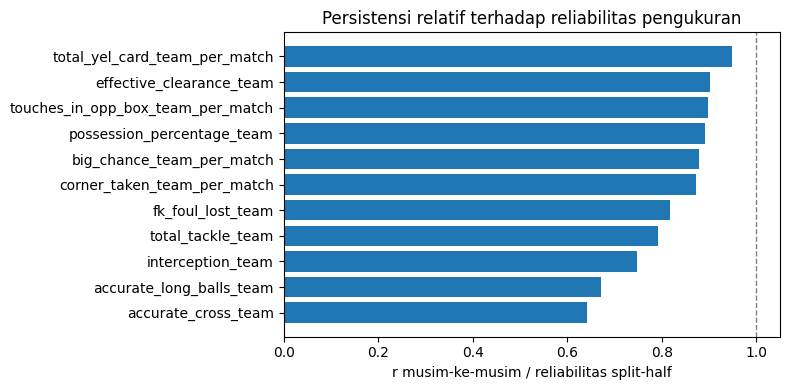

In [31]:
# Reliabilitas fitur: split-half acak berulang dalam setiap club-season.
MATCH_FOR_FEATURE = {
    "accurate_cross_team": "accurate_crosses",
    "accurate_long_balls_team": "long_balls_accurate",
    "effective_clearance_team": "clearances",
    "fk_foul_lost_team": "fouls",
    "interception_team": "interceptions",
    "total_tackle_team": "matchstats_headers_tackles",
    "possession_percentage_team": "ballpossesion",
    "big_chance_team_per_match": "big_chance",
    "corner_taken_team_per_match": "corners",
    "total_yel_card_team_per_match": "yellow_cards",
    "touches_in_opp_box_team_per_match": "touches_opp_box",
}
REL_KEY = ["league", "season_norm", "team_norm"]
rel_map = {f_: m_ for f_, m_ in MATCH_FOR_FEATURE.items()
           if f_ in SELECTED_FEATURES and m_ in match_long.columns}
tanpa_padanan = [f_ for f_ in SELECTED_FEATURES if f_ not in rel_map]
print("Fitur tanpa padanan match-level (tidak dihitung):", tanpa_padanan or "tidak ada")

ml = match_long.sort_values("date_local").copy().reset_index(drop=True)
rel_cols = list(rel_map.values())
for c_ in rel_cols:
    ml[c_] = pd.to_numeric(ml[c_], errors="coerce")

def _within_group_z(df, group_cols):
    """Z-score per kelompok; kelompok dengan SD nol menjadi 0."""
    grouped = df.groupby(group_cols)
    mu = grouped.transform("mean")
    sd = grouped.transform(lambda x: x.std(ddof=0)).replace(0, np.nan)
    return ((df - mu) / sd).replace([np.inf, -np.inf], np.nan)

def _safe_corr(x, y):
    x = pd.Series(x, dtype=float); y = pd.Series(y, dtype=float)
    ok = x.notna() & y.notna()
    if ok.sum() < 3 or x[ok].std(ddof=0) == 0 or y[ok].std(ddof=0) == 0:
        return np.nan
    return float(np.corrcoef(x[ok], y[ok])[0, 1])

N_SPLIT_REPS = 100  # tingkatkan, misalnya ke 500, untuk analisis final bila waktu komputasi memungkinkan
rng_rel = np.random.default_rng(2026)
rel_split_corr = {f_: [] for f_ in rel_map}
for rep in range(N_SPLIT_REPS):
    tmp = ml[REL_KEY + rel_cols].copy()
    tmp["_half"] = -1
    # Acak urutan pertandingan secara terpisah di setiap club-season.
    for _, idx in tmp.groupby(REL_KEY, sort=False).groups.items():
        idx = np.asarray(list(idx))
        perm = rng_rel.permutation(idx)
        tmp.loc[perm, "_half"] = np.arange(len(perm)) % 2

    half_means = tmp.groupby(REL_KEY + ["_half"])[rel_cols].mean()
    if half_means.empty:
        continue
    # Normalisasi dalam liga-musim dan setengah-sampel untuk mengukur posisi relatif.
    zhalf = half_means.groupby(level=[0, 1, 3]).transform(
        lambda s: (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else s * 0
    )
    try:
        h0 = zhalf.xs(0, level="_half")
        h1 = zhalf.xs(1, level="_half")
    except KeyError:
        continue
    common = h0.index.intersection(h1.index)
    for feat, mcol in rel_map.items():
        r = _safe_corr(h0.loc[common, mcol], h1.loc[common, mcol])
        if np.isfinite(r):
            rel_split_corr[feat].append(r)

# Korelasi antarmusim dari rerata semua pertandingan dalam setiap club-season.
full_m = ml.groupby(REL_KEY)[rel_cols].mean()
zfull = _within_group_z(full_m, ["league", "season_norm"]).reset_index()
season_order = sorted(ml["season_norm"].dropna().unique())
rel_rows = []
for feat, mcol in rel_map.items():
    rs = np.asarray(rel_split_corr[feat], dtype=float)
    rs = rs[np.isfinite(rs)]
    if len(rs):
        # Fisher-z averaging menghindari bias rata-rata langsung korelasi.
        r_half = float(np.tanh(np.arctanh(np.clip(rs, -0.999999, 0.999999)).mean()))
        r_sb = (2 * r_half / (1 + r_half)) if (1 + r_half) != 0 else np.nan
    else:
        r_half, r_sb = np.nan, np.nan

    xs, ys = [], []
    for (lg, tn), gr in zfull.groupby(["league", "team_norm"]):
        gr = gr.set_index("season_norm")
        for s0, s1 in zip(season_order[:-1], season_order[1:]):
            if s0 in gr.index and s1 in gr.index:
                a, b = gr.loc[s0, mcol], gr.loc[s1, mcol]
                if pd.notna(a) and pd.notna(b):
                    xs.append(a); ys.append(b)
    r_yy = _safe_corr(xs, ys)
    rel_rows.append({
        "fitur": feat, "r_split_half_mean": r_half,
        "reliabilitas_dalam_musim_SB": r_sb,
        "r_musim_ke_musim": r_yy,
        "rasio_persistensi_reliabilitas": r_yy / r_sb if pd.notna(r_yy) and pd.notna(r_sb) and r_sb != 0 else np.nan,
        "n_replikasi_valid": len(rs), "n_pasangan_musim": len(xs)
    })
rel_table = pd.DataFrame(rel_rows).set_index("fitur")
display(rel_table.round(3))
print("Rata-rata rasio deskriptif:", round(rel_table["rasio_persistensi_reliabilitas"].mean(), 3))
print("Catatan: rasio dapat >1; jangan dipotong ke 1.")

fig, ax = plt.subplots(figsize=(8, max(4, .35 * len(rel_table))))
rt = rel_table.sort_values("rasio_persistensi_reliabilitas")
ax.barh(rt.index, rt["rasio_persistensi_reliabilitas"])
ax.axvline(1, color="gray", lw=1, ls="--")
ax.set_xlabel("r musim-ke-musim / reliabilitas split-half")
ax.set_title("Persistensi relatif terhadap reliabilitas pengukuran")
plt.tight_layout(); plt.show()


**Temuan:** rasio rata-rata ≈ 0,83 (median ≈ 0,89) pada 331 pasangan klub-musim berturut. Setelah noise pengukuran diperhitungkan, sekitar 83% dari stabilitas yang mungkin dicapai memang bertahan antarmusim. Paling stabil: sapuan (0,94), sentuhan di kotak lawan (0,93), peluang besar (0,91), tendangan sudut (0,90), penguasaan bola (0,89). Paling kurang stabil: umpan silang akurat (0,66), umpan panjang akurat (0,67), intersepsi (0,72), dan tekel (0,77).

**Catatan:** (1) kartu kuning punya rasio tinggi (0,96) tetapi reliabilitas dalam musim rendah (0,54); rasio yang dibagi reliabilitas kecil kurang pasti, jangan ditafsirkan berlebihan. (2) Pasangan hanya mencakup klub yang ada di liga yang sama dua musim berturut-turut, jadi klub promosi dan degradasi tidak masuk. (3) Ini stabilitas posisi **relatif** klub (z-score dalam liga-musim); stabilitas nilai absolut tidak diuji di bagian ini.

## 22. Analisis PCA-Varimax pada unit klub-musim (pembanding)

Bagian ini merupakan analisis PCA-Varimax pada fitur agregat klub-musim. Hasilnya menjadi pembanding terhadap analisis utama pada unit klub-pertandingan di Bagian 22b–22e. Keduanya tidak boleh dianggap sebagai satu rangkaian skor yang sama karena unit pembentukan PCA berbeda.

**Pertanyaan:** apakah skor komponen gaya klub-musim menunjukkan pergeseran antarmusim setelah memperhitungkan klub yang muncul berulang serta mengontrol liga dan kekuatan tim?

**Cara:** PCA-Varimax dibentuk dari fitur klub-musim dengan standardisasi global; skor komponen kemudian dianalisis menggunakan model campuran dengan musim, liga, kekuatan tim, dan intersep acak klub.

**Batasan:** model menunjukkan pergeseran skor terukur, bukan penyebabnya. Perubahan perilaku tim dan perubahan pencatatan provider sama-sama mungkin.

**Penjelasan kode:** Menyusun komponen utama dari fitur gaya bermain klub-musim, lalu memutar hasilnya agar ciri setiap komponen lebih mudah dibaca. Jumlah komponen dipilih berdasarkan aturan nilai eigen yang digunakan dalam notebook.

**Output yang dihasilkan:** Menampilkan nilai eigen, jumlah komponen yang dipertahankan, persentase variasi yang dijelaskan, dan hubungan fitur dengan komponen.

In [32]:
def varimax(L, gamma=1.0, q=100, tol=1e-8):
    p, k = L.shape
    R = np.eye(k); d = 0
    for _ in range(q):
        d_old = d
        Lr = L @ R
        u, s_, vh = np.linalg.svd(L.T @ (Lr ** 3 - (gamma / p) * Lr @ np.diag(np.sum(Lr ** 2, axis=0))))
        R = u @ vh; d = s_.sum()
        if d_old != 0 and d / d_old < 1 + tol:
            break
    return L @ R, R

X_pool = build_matrix("pooled", False)
eig = PCA(random_state=42).fit(X_pool.values).explained_variance_
print("Nilai eigen:", eig.round(2))
N_COMP = int((eig > 1).sum())          # kriteria Kaiser; ubah manual bila perlu
print("Jumlah komponen (Kaiser):", N_COMP)

pca_m = PCA(n_components=N_COMP, random_state=42).fit(X_pool.values)
L_ = pca_m.components_.T * np.sqrt(pca_m.explained_variance_)
S_ = pca_m.transform(X_pool.values) / np.sqrt(pca_m.explained_variance_)
Lrot, Rrot = varimax(L_)
Srot = S_ @ Rrot
comp_cols = [f"P{i+1}" for i in range(N_COMP)]
load_df = pd.DataFrame(Lrot, index=SELECTED_FEATURES, columns=comp_cols)
score_df = pd.DataFrame(Srot, index=team.index, columns=comp_cols)
var_expl = (Lrot ** 2).sum(axis=0) / len(SELECTED_FEATURES)
print("Varians dijelaskan per komponen (setelah rotasi):", dict(zip(comp_cols, var_expl.round(3))), "| total: %.2f" % var_expl.sum())

shown = load_df.round(2).where(load_df.abs() >= .4, "")
print("Loading dengan |nilai| >= 0,4 (sel kosong = loading lebih kecil dari 0,4)")
display(shown[(shown != "").any(axis=1)])

Nilai eigen: [4.21 1.72 1.29 1.03 0.92 0.5  0.43 0.37 0.27 0.17 0.11]
Jumlah komponen (Kaiser): 4
Varians dijelaskan per komponen (setelah rotasi): {'P1': np.float64(0.332), 'P2': np.float64(0.141), 'P3': np.float64(0.132), 'P4': np.float64(0.145)} | total: 0.75
Loading dengan |nilai| >= 0,4 (sel kosong = loading lebih kecil dari 0,4)


,P1,P2,P3,P4
accurate_cross_team,0.41,,,0.47
accurate_long_balls_team,,0.88,,
effective_clearance_team,-0.44,-0.69,,
fk_foul_lost_team,,,,0.76
interception_team,,,0.78,
total_tackle_team,,,0.85,
possession_percentage_team,0.8,,,
big_chance_team_per_match,0.85,,,
corner_taken_team_per_match,0.87,,,
total_yel_card_team_per_match,,,,0.78


**Penjelasan kode:** Menguji apakah skor komponen gaya bermain berubah dari musim ke musim dengan tetap memperhitungkan liga, kekuatan tim, dan perbedaan karakter tiap klub. Musim diuji sebagai urutan waktu maupun sebagai kategori.

**Output yang dihasilkan:** Menampilkan perkiraan perubahan skor setiap komponen, rentang ketidakpastian, dan hasil pengujian statistik.

In [33]:
import statsmodels.formula.api as smf
import warnings

md_df = pd.DataFrame({
    "season": team["season"].values, "league": team["league"].values,
    "klub": (team["league"] + "|" + team["team_norm"]).values,
})
sx = team["xg_diff_per_match"]
md_df["strength"] = ((sx - sx.mean()) / sx.std(ddof=0)).values
for c_ in comp_cols:
    md_df[c_] = score_df[c_].values

me_rows, icc_rows = [], []
for c_ in comp_cols:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        mdl = smf.mixedlm(f"{c_} ~ C(season) + C(league) + strength", md_df, groups=md_df["klub"]).fit(reml=True)
    for k_ in mdl.params.index:
        if k_.startswith("C(season)"):
            me_rows.append({"komponen": c_, "musim": k_.split("[T.")[1][:-1], "koef_SD": mdl.params[k_], "p": mdl.pvalues[k_]})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        mdl0 = smf.mixedlm(f"{c_} ~ C(season) + C(league)", md_df, groups=md_df["klub"]).fit(reml=True)
    icc_rows.append({"komponen": c_,
                     "ICC_tanpa_kekuatan": float(mdl0.cov_re.iloc[0, 0] / (mdl0.cov_re.iloc[0, 0] + mdl0.scale)),
                     "ICC_dengan_kekuatan": float(mdl.cov_re.iloc[0, 0] / (mdl.cov_re.iloc[0, 0] + mdl.scale)),
                     "koef_kekuatan": mdl.params["strength"], "p_kekuatan": mdl.pvalues["strength"]})
me_table = pd.DataFrame(me_rows)
icc_table = pd.DataFrame(icc_rows).set_index("komponen")
alpha_bonf = 0.05 / len(me_table)
piv = me_table.pivot(index="komponen", columns="musim", values="koef_SD").round(2).astype(str)
sig = me_table.pivot(index="komponen", columns="musim", values="p") < alpha_bonf
print("Efek musim (SD skor) terhadap musim pertama; * = p < %.4f (Bonferroni untuk %d uji)" % (alpha_bonf, len(me_table)))
display(piv + np.where(sig, "*", ""))
print("\nICC klub (porsi variasi skor yang berasal dari perbedaan antar-klub) tanpa dan dengan kontrol kekuatan, serta efek kekuatan:")
display(icc_table.round(3))

Efek musim (SD skor) terhadap musim pertama; * = p < 0.0031 (Bonferroni untuk 16 uji)


musim,2022/2023,2023/2024,2024/2025,2025/2026
komponen,,,,
P1,0.16,0.45*,0.41*,0.32*
P2,-0.47*,-1.06*,-1.75*,-1.86*
P3,-0.13,-0.36*,-0.41*,-0.54*
P4,0.16,0.47*,0.29,0.12



ICC klub (porsi variasi skor yang berasal dari perbedaan antar-klub) tanpa dan dengan kontrol kekuatan, serta efek kekuatan:


,ICC_tanpa_kekuatan,ICC_dengan_kekuatan,koef_kekuatan,p_kekuatan
komponen,,,,
P1,0.736,0.232,0.803,0.000
P2,0.431,0.392,0.172,0.000
P3,0.316,0.291,-0.094,0.040
P4,0.407,0.401,-0.046,0.347


**Penjelasan kode:** Membuat pembanding dengan menyamakan skala di dalam setiap liga-musim. Karena rata-rata tiap liga-musim dibuat setara, bagian ini memeriksa bahwa perbedaan rata-rata antarmusim memang tidak lagi terlihat pada skala tersebut.

**Output yang dihasilkan:** Menampilkan efek musim yang diharapkan mendekati nol sebagai pemeriksaan pembanding.

In [34]:
# Pembanding: skor komponen utama dari standardisasi DALAM liga-musim. Efek musim harus ~0 secara matematis.
Xw = build_matrix("within_league_season", False)
pw = PCA(n_components=1, random_state=42).fit_transform(Xw.values)[:, 0]
chk = md_df.copy(); chk["skor_dalam"] = pw
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mw = smf.mixedlm("skor_dalam ~ C(season) + C(league) + strength", chk, groups=chk["klub"]).fit(reml=True)
print("Efek musim pada skor dalam-liga-musim (harus ~0):", {k_.split("[T.")[1][:-1]: round(v, 3) for k_, v in mw.params.items() if k_.startswith("C(season)")})

Efek musim pada skor dalam-liga-musim (harus ~0): {'2022/2023': 0.017, '2023/2024': -0.0, '2024/2025': 0.037, '2025/2026': 0.049}


**Komponen (Varimax, 4 komponen, total varians ≈ 75%):** P1 dominasi serangan dan wilayah (sentuhan di kotak lawan, tendangan sudut, peluang besar, penguasaan bola; sapuan berarah negatif); P2 umpan panjang vs sapuan (umpan panjang akurat positif, sapuan negatif); P3 aksi bertahan aktif (tekel dan intersepsi); P4 fisik dan disiplin (pelanggaran, kartu kuning, umpan silang). Nama komponen adalah tafsiran dari loading dan boleh diubah. Kriteria Kaiser memberi 4 komponen dengan nilai eigen komponen keempat hanya 1,03, jadi jumlah komponen sensitif terhadap kriteria.

**Efek musim:** P2 turun besar dan konsisten, dari −0,47 SD (2022/23) sampai −1,86 SD (2025/26), semuanya signifikan setelah Bonferroni. P2 memuat sapuan dengan arah negatif, dan sapuan naik ≈ 45% pada bagian 2a. P1 naik moderat (+0,32 sampai +0,45 SD sejak 2023/24), P3 turun (−0,36 sampai −0,54 SD sejak 2023/24), dan P4 tidak konsisten (hanya 2023/24 signifikan).

**Kekuatan tim:** terkait sangat kuat dengan P1 (koefisien 0,80 SD per SD kekuatan, p < 0,001), jauh lebih kecil pada komponen lain.

**ICC klub:** tanpa kontrol kekuatan, 74% variasi P1 berasal dari perbedaan antar-klub, sedangkan P2 43%, P3 32%, P4 41%. Setelah kekuatan dikontrol, ICC P1 turun ke 23%: hampir seluruh perbedaan antar-klub yang stabil pada P1 sama dengan perbedaan kekuatan. ICC komponen lain hampir tidak berubah.

**Cara membaca:** model menunjukkan **bahwa** skor gaya bergeser sistematis antarmusim, terutama pada komponen yang memuat sapuan, bukan **mengapa**. Perubahan perilaku tim dan perubahan cara pencatatan oleh provider sama-sama mungkin; data ini tidak bisa memilih di antaranya. Pembanding terakhir (skor dalam liga-musim) menunjukkan efek musim hampir nol (≤ 0,05 SD), jadi analisis gaya relatif tidak boleh dipakai untuk mengklaim "tidak ada perubahan".

## 22b. Analisis utama PCA-Varimax pada unit klub-pertandingan

PCA dibentuk dari seluruh observasi klub-pertandingan menggunakan satu standardisasi global. Parameter transformasi dan bobot skor yang sama digunakan untuk membentuk skor klub-musim, menguji tipe gaya setelah koreksi kekuatan, serta menganalisis perubahan dan persistensi antarmusim.

Bagian ini menjadi dasar analisis longitudinal utama karena skor setiap musim dan liga berada pada skala yang konsisten.

**Penjelasan kode:** Membentuk komponen gaya bermain dari data setiap tim pada setiap pertandingan dengan menggunakan skala penyamaan yang sama untuk seluruh data. Cara ini membuat skor dari musim dan liga berbeda dapat dibandingkan pada skala yang konsisten.

**Output yang dihasilkan:** Menampilkan pemeriksaan nilai kosong, hasil komponen gaya bermain, dan ringkasan fitur yang membentuk setiap komponen.

In [35]:
# 22b-1. PCA-Varimax pada unit klub-pertandingan (: standardisasi global)
KEY_CS = ["league", "season_norm", "team_norm"]
mm = match_long.copy()
base_cols = ["passes", "accurate_passes_pct", "opposition_half_passes", "own_half_passes", "long_balls_accurate",
             "accurate_crosses", "total_shots", "shots_inside_box", "big_chance", "corners", "interceptions",
             "clearances", "shot_blocks", "matchstats_headers_tackles", "ground_duels_won", "aerials_won",
             "dribbles_succeeded", "fouls", "offsides", "ballpossesion", "player_throws", "expected_goals"]
assert all(c in mm.columns for c in base_cols), [c for c in base_cols if c not in mm.columns]
for c in base_cols:
    mm[c] = pd.to_numeric(mm[c], errors="coerce")

mm["opp_half_share"] = mm["opposition_half_passes"] / (mm["opposition_half_passes"] + mm["own_half_passes"])
mm["long_ball_share"] = mm["long_balls_accurate"] / mm["passes"]
mm["inside_box_share"] = mm["shots_inside_box"] / mm["total_shots"].replace(0, np.nan)
mm["cross_per_pass"] = mm["accurate_crosses"] / mm["passes"]

# Selisih xG per pertandingan: hanya dipakai sebagai ukuran kekuatan, BUKAN fitur gaya.
n_side = mm.groupby("fotmob_id")["expected_goals"].transform("count")
tot_xg = mm.groupby("fotmob_id")["expected_goals"].transform("sum")
mm["xg_diff_m"] = np.where(n_side == 2, 2 * mm["expected_goals"] - tot_xg, np.nan)

STYLE_M = ["passes", "accurate_passes_pct", "opp_half_share", "long_ball_share", "cross_per_pass",
           "total_shots", "inside_box_share", "big_chance", "corners", "interceptions", "clearances",
           "shot_blocks", "matchstats_headers_tackles", "ground_duels_won", "aerials_won",
           "dribbles_succeeded", "fouls", "offsides", "ballpossesion", "player_throws"]
Xm = mm[STYLE_M].replace([np.inf, -np.inf], np.nan)
miss = (Xm.isna().mean() * 100).round(2)
print("Nilai hilang per fitur (%):", miss[miss > 0].to_dict() or "tidak ada")
Xm = Xm.fillna(Xm.median())
print("Unit klub-pertandingan:", Xm.shape)

# Satu parameter standardisasi untuk semua liga dan musim.
# Parameter ini menjadi dasar PCA, skor relatif, dan skor longitudinal.
X_MEAN = Xm.mean()
X_STD = Xm.std(ddof=0).replace(0, 1)
Zm_pool = ((Xm - X_MEAN) / X_STD).fillna(0)

pca_mm = PCA(random_state=42).fit(Zm_pool.values)
eig_m = pca_mm.explained_variance_
N_COMP_M = int((eig_m > 1).sum())
print("Nilai eigen:", eig_m.round(2))
print("Jumlah komponen (Kaiser):", N_COMP_M)
Lm = pca_mm.components_[:N_COMP_M].T * np.sqrt(eig_m[:N_COMP_M])
Lm_rot, Rm_rot = varimax(Lm)

# Nama komponen: interpretasi dari fitur jangkar; tanda diselaraskan.
ANCHOR = {"Membangun dari belakang": "passes", "Intensitas duel": "ground_duels_won",
          "Serangan di area lawan": "total_shots", "Kualitas peluang": "inside_box_share",
          "Udara dan bola mati": "aerials_won", "Defensif fisik": "fouls"}
fi = {f: i for i, f in enumerate(STYLE_M)}
names_m, used = {}, set()
for nm, f in ANCHOR.items():
    j = int(np.argmax(np.abs(Lm_rot[fi[f]])))
    if j not in used:
        used.add(j)
        names_m[j] = nm
        if Lm_rot[fi[f], j] < 0:
            Lm_rot[:, j] *= -1
COMP_M = [names_m.get(j, f"M{j+1}") for j in range(N_COMP_M)]
print("Nama komponen (tafsiran):", COMP_M)
print("Jumlah komponen mengikuti Kaiser; interpretasi nama komponen wajib diperiksa dari loading, bukan diasumsikan tetap enam.")

var_m = (Lm_rot ** 2).sum(axis=0) / len(STYLE_M)
print("Varians dijelaskan per komponen (setelah rotasi):", dict(zip(COMP_M, var_m.round(3))), "| total: %.2f" % var_m.sum())
load_m = pd.DataFrame(Lm_rot, index=STYLE_M, columns=COMP_M)
shown = load_m.round(2).where(load_m.abs() >= .4, "")
print("Loading dengan |nilai| >= 0,4")
display(shown[(shown != "").any(axis=1)])

# Bobot regresi dihitung pada korelasi fitur dengan skala global yang sama.
R_features = np.corrcoef(Zm_pool.values.T)
Wm = np.linalg.pinv(R_features, rcond=1e-10) @ Lm_rot

# Skor relatif liga-musim: pusatkan Z global pada mean liga-musim,
# tetapi JANGAN standardisasi ulang dengan SD liga-musim.
grp = [mm["league"], mm["season_norm"]]
Zm_win = Zm_pool.groupby(grp).transform(lambda s: s - s.mean()).fillna(0)


Nilai hilang per fitur (%): {'passes': 0.01, 'accurate_passes_pct': 0.01, 'opp_half_share': 0.01, 'long_ball_share': 0.01, 'cross_per_pass': 0.01, 'inside_box_share': 0.03, 'big_chance': 0.01, 'interceptions': 0.01, 'clearances': 0.01, 'shot_blocks': 0.01, 'matchstats_headers_tackles': 0.01, 'ground_duels_won': 0.01, 'aerials_won': 0.01, 'dribbles_succeeded': 0.01, 'fouls': 0.01, 'offsides': 0.01, 'player_throws': 0.01}
Unit klub-pertandingan: (17816, 20)
Nilai eigen: [4.52 2.24 1.93 1.49 1.11 1.08 0.98 0.92 0.85 0.84 0.72 0.64 0.61 0.56
 0.48 0.4  0.28 0.16 0.14 0.06]
Jumlah komponen (Kaiser): 6
Nama komponen (tafsiran): ['Membangun dari belakang', 'Serangan di area lawan', 'Intensitas duel', 'Kualitas peluang', 'Udara dan bola mati', 'Defensif fisik']
Jumlah komponen mengikuti Kaiser; interpretasi nama komponen wajib diperiksa dari loading, bukan diasumsikan tetap enam.
Varians dijelaskan per komponen (setelah rotasi): {'Membangun dari belakang': np.float64(0.197), 'Serangan di area 

,Membangun dari belakang,Serangan di area lawan,Intensitas duel,Kualitas peluang,Udara dan bola mati,Defensif fisik
passes,0.93,,,,,
accurate_passes_pct,0.83,,,,,
opp_half_share,,0.65,,,,
long_ball_share,-0.69,,,,,
cross_per_pass,,0.68,,,,
total_shots,,0.75,,,,
inside_box_share,,,,0.8,,
big_chance,,,,0.65,,
corners,,0.69,,,,
clearances,-0.46,,,,,-0.55


**Penjelasan kode:** Menggabungkan skor pertandingan menjadi gambaran gaya bermain setiap klub pada setiap musim, lalu membandingkannya dengan ukuran kekuatan tim. Langkah ini membantu memisahkan ciri gaya bermain dari sekadar kuat atau lemahnya sebuah klub.

**Output yang dihasilkan:** Menampilkan 484 profil klub-musim, hubungan setiap komponen dengan kekuatan tim, dan ringkasan skor gaya klub.

In [36]:
# 22b-2. Skor relatif per klub-musim dan hubungannya dengan kekuatan tim
# Zm_win telah dipusatkan per liga-musim, tetapi memakai skala global dan bobot PCA global.
Sm_win = pd.DataFrame(Zm_win.values @ Wm, columns=COMP_M, index=mm.index)
cs_m = (pd.concat([mm[KEY_CS], Sm_win, mm[["xg_diff_m"]]], axis=1)
          .groupby(KEY_CS).mean().reset_index())
print("Klub-musim:", len(cs_m), "| klub unik:", cs_m["team_norm"].nunique())
corr_str = cs_m[COMP_M + ["xg_diff_m"]].corr()["xg_diff_m"].drop("xg_diff_m")
display(corr_str.round(2).to_frame("r dengan kekuatan tim (selisih xG)"))
print("Komponen dengan |r| kecil adalah dimensi gaya yang relatif bebas dari kekuatan tim.")


Klub-musim: 484 | klub unik: 130


,r dengan kekuatan tim (selisih xG)
Membangun dari belakang,0.74
Serangan di area lawan,0.45
Intensitas duel,0.12
Kualitas peluang,0.61
Udara dan bola mati,-0.38
Defensif fisik,0.17


Komponen dengan |r| kecil adalah dimensi gaya yang relatif bebas dari kekuatan tim.


**Penjelasan kode:** Mengelompokkan klub-musim berdasarkan skor komponen gaya bermain setelah pengaruh kekuatan tim dikurangi. Beberapa jumlah kelompok diuji agar terlihat apakah tipe gaya bermain masih dapat dibedakan setelah penyesuaian tersebut.

**Output yang dihasilkan:** Menampilkan perbandingan kualitas dan kestabilan hasil clustering pada skor mentah dan skor yang sudah dikoreksi.

In [37]:
# 22c. Tipe gaya: klasterisasi pada skor yang sudah dibersihkan dari kekuatan tim
A_ = cs_m[COMP_M].values
Xs_ = np.c_[np.ones(len(cs_m)), cs_m["xg_diff_m"].values]
resid_m = A_ - Xs_ @ np.linalg.lstsq(Xs_, A_, rcond=None)[0]       # residu terhadap kekuatan
Rz = (resid_m - resid_m.mean(0)) / resid_m.std(0)
Az = (A_ - A_.mean(0)) / A_.std(0)

def eval_k(M, ks=range(2, 7), reps=30, seed=42):
    rng_ = np.random.default_rng(seed); out = []
    for k in ks:
        base = KMeans(n_clusters=k, n_init=30, random_state=42).fit_predict(M)
        sc = []
        for rep in range(reps):
            idx = np.sort(rng_.choice(len(M), int(0.8 * len(M)), replace=False))
            lab = KMeans(n_clusters=k, n_init=10, random_state=rep).fit_predict(M[idx])
            sc.append(adjusted_rand_score(base[idx], lab))
        out.append({"k": k, "silhouette": silhouette_score(M, base), "ARI_mean": np.mean(sc), "ARI_sd": np.std(sc)})
    return pd.DataFrame(out).set_index("k").round(3)

print("Skor mentah (belum dikoreksi kekuatan):"); display(eval_k(Az))
print("Skor bebas kekuatan (residu terhadap selisih xG):"); display(eval_k(Rz))
print("Silhouette < 0,3 di semua k: struktur kelompok lemah; tipe di bawah adalah kecenderungan, bukan kategori yang terpisah tegas.")

FINAL_K_TYPE = 3
km_t = KMeans(n_clusters=FINAL_K_TYPE, n_init=50, random_state=42).fit(Rz)
cs_m["tipe_k"] = km_t.labels_
prof_t = pd.DataFrame(Rz, columns=COMP_M).assign(tipe_k=km_t.labels_).groupby("tipe_k").mean()
type_names = {k: f"Tipe {k}" for k in prof_t.index}
need = ["Membangun dari belakang", "Serangan di area lawan"]
if FINAL_K_TYPE == 3 and all(n in prof_t.columns for n in need):
    a_ = prof_t["Membangun dari belakang"].idxmax()
    c_ = prof_t.drop(index=a_)["Serangan di area lawan"].idxmax()
    b_ = [k for k in prof_t.index if k not in (a_, c_)][0]
    type_names = {a_: "A. Penguasa bola / membangun dari belakang", b_: "B. Serangan selektif",
                  c_: "C. Langsung (silang, udara, bola mati)"}
cs_m["tipe"] = cs_m["tipe_k"].map(type_names)
prof_t.index = [type_names[k] for k in prof_t.index]
print("Profil tipe (rerata skor residu, dalam SD):"); display(prof_t.round(2))
summ_t = cs_m.groupby("tipe").agg(n=("tipe", "size"), rerata_xg_diff=("xg_diff_m", "mean")).round(2)
print("Ukuran tipe dan rerata selisih xG (harus hampir sama bila kekuatan benar-benar dikoreksi):"); display(summ_t)
last_s = sorted(cs_m["season_norm"].unique())[-2]
print("Contoh klub, musim", last_s, "(nama tipe adalah tafsiran; periksa daftar penuhnya):")
for t_, g_ in cs_m[cs_m["season_norm"] == last_s].groupby("tipe"):
    print(" ", t_, ":", ", ".join(sorted(g_["team_norm"])[:12]))

Skor mentah (belum dikoreksi kekuatan):


,silhouette,ARI_mean,ARI_sd
k,,,
2,0.194,0.930,0.057
3,0.169,0.916,0.050
4,0.167,0.796,0.088
5,0.157,0.718,0.099
6,0.157,0.549,0.137


Skor bebas kekuatan (residu terhadap selisih xG):


,silhouette,ARI_mean,ARI_sd
k,,,
2,0.221,0.969,0.023
3,0.169,0.879,0.087
4,0.157,0.763,0.153
5,0.155,0.623,0.121
6,0.154,0.692,0.126


Silhouette < 0,3 di semua k: struktur kelompok lemah; tipe di bawah adalah kecenderungan, bukan kategori yang terpisah tegas.
Profil tipe (rerata skor residu, dalam SD):


,Membangun dari belakang,Serangan di area lawan,Intensitas duel,Kualitas peluang,Udara dan bola mati,Defensif fisik
B. Serangan selektif,-0.15,-0.38,-0.49,0.93,0.02,-0.38
A. Penguasa bola / membangun dari belakang,0.85,-0.52,0.47,-0.29,-0.74,-0.28
"C. Langsung (silang, udara, bola mati)",-0.81,0.90,-0.11,-0.46,0.80,0.63


Ukuran tipe dan rerata selisih xG (harus hampir sama bila kekuatan benar-benar dikoreksi):


,n,rerata_xg_diff
tipe,,
A. Penguasa bola / membangun dari belakang,181,0.03
B. Serangan selektif,138,-0.00
"C. Langsung (silang, udara, bola mati)",165,-0.02


Contoh klub, musim 2024/25 (nama tipe adalah tafsiran; periksa daftar penuhnya):
  A. Penguasa bola / membangun dari belakang : angers, aston villa, barcelona, bayern munich, borussia dortmund, brighton & hove albion, celta vigo, como, girona, ipswich town, juventus, las palmas
  B. Serangan selektif : atalanta, atletico madrid, borussia monchengladbach, brentford, cagliari, eintracht frankfurt, espanyol, fiorentina, freiburg, genoa, holstein kiel, inter
  C. Langsung (silang, udara, bola mati) : afc bournemouth, arsenal, athletic club, augsburg, auxerre, bayer leverkusen, bochum, bologna, brest, chelsea, crystal palace, deportivo alaves


**Penjelasan kode:** Mengukur perubahan skor komponen gaya bermain dari musim ke musim dengan tetap mempertahankan skala global. Model juga memperhitungkan liga, kekuatan tim, dan perbedaan antar klub.

**Output yang dihasilkan:** Menampilkan arah dan besarnya perubahan per musim untuk setiap komponen, beserta rentang kepercayaan dan nilai signifikansinya.

In [38]:
# 22d. Pergeseran longitudinal: skor global (mempertahankan tren antarmusim)
# Zm_pool dan Wm sudah dibentuk pada Cell 66 dari standardisasi/PCA global yang sama.
Sm_pool = pd.DataFrame(Zm_pool.values @ Wm, columns=COMP_M, index=mm.index)
cs_p = (pd.concat([mm[KEY_CS], Sm_pool], axis=1).groupby(KEY_CS).mean().reset_index()
          .merge(cs_m[KEY_CS + ["xg_diff_m"]], on=KEY_CS))
cs_p["strength"] = (cs_p["xg_diff_m"] - cs_p["xg_diff_m"].mean()) / cs_p["xg_diff_m"].std(ddof=0)
cs_p["klub"] = cs_p["league"] + "|" + cs_p["team_norm"]
s_order = sorted(cs_p["season_norm"].unique())
cs_p["t"] = cs_p["season_norm"].map({s: i for i, s in enumerate(s_order)})

tr_rows, se_rows = [], []
for j, nm in enumerate(COMP_M):
    cs_p[f"m{j+1}"] = cs_p[nm]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        mt = smf.mixedlm(f"m{j+1} ~ t + C(league) + strength", cs_p, groups=cs_p["klub"]).fit(reml=True)
        ms = smf.mixedlm(f"m{j+1} ~ C(season_norm) + C(league) + strength", cs_p, groups=cs_p["klub"]).fit(reml=True)
    ci = mt.conf_int().loc["t"]
    tr_rows.append({"komponen": nm, "perubahan_per_musim_SD": mt.params["t"], "CI95_bawah": ci[0], "CI95_atas": ci[1],
                    "p": mt.pvalues["t"], "koef_kekuatan": mt.params["strength"]})
    for k_ in ms.params.index:
        if k_.startswith("C(season_norm)"):
            se_rows.append({"komponen": nm, "musim": k_.split("[T.")[1][:-1], "koef_SD": ms.params[k_], "p": ms.pvalues[k_]})
drift_trend = pd.DataFrame(tr_rows).set_index("komponen")
drift_season = pd.DataFrame(se_rows)
print("Tren linear per musim (model campuran: skor global ~ musim + liga + kekuatan + (1|klub)); satuan = SD skor global:")
display(drift_trend.round(3))
alpha_b = 0.05 / len(drift_season)
piv_s = drift_season.pivot(index="komponen", columns="musim", values="koef_SD").round(2).astype(str)
sig_s = drift_season.pivot(index="komponen", columns="musim", values="p") < alpha_b
print("Efek musim terhadap musim pertama; * = p < %.4f (Bonferroni, %d uji)" % (alpha_b, len(drift_season)))
display(piv_s + np.where(sig_s, "*", ""))
print("Penyebab pergeseran tidak diketahui: perilaku tim atau perubahan pencatatan penyedia data.")


Tren linear per musim (model campuran: skor global ~ musim + liga + kekuatan + (1|klub)); satuan = SD skor global:


,perubahan_per_musim_SD,CI95_bawah,CI95_atas,p,koef_kekuatan
komponen,,,,,
Membangun dari belakang,0.036,0.018,0.055,0.000,0.318
Serangan di area lawan,-0.020,-0.035,-0.005,0.009,0.157
Intensitas duel,-0.109,-0.126,-0.091,0.000,0.030
Kualitas peluang,0.076,0.063,0.089,0.000,0.177
Udara dan bola mati,-0.057,-0.072,-0.041,0.000,-0.075
Defensif fisik,-0.155,-0.169,-0.141,0.000,0.051


Efek musim terhadap musim pertama; * = p < 0.0021 (Bonferroni, 24 uji)


musim,2022/23,2023/24,2024/25,2025/26
komponen,,,,
Defensif fisik,-0.05,-0.24*,-0.46*,-0.57*
Intensitas duel,-0.02,-0.11,-0.28*,-0.41*
Kualitas peluang,0.07,0.17*,0.29*,0.27*
Membangun dari belakang,0.04,0.15*,0.14*,0.13*
Serangan di area lawan,-0.03,-0.0,-0.08,-0.07
Udara dan bola mati,-0.09,-0.2*,-0.24*,-0.21*


Penyebab pergeseran tidak diketahui: perilaku tim atau perubahan pencatatan penyedia data.


**Penjelasan kode:** Membandingkan kestabilan skor gaya klub dari satu musim ke musim berikutnya dengan tingkat keandalan pengukuran dalam satu musim. Reliabilitas dihitung melalui pembagian pertandingan secara acak yang diulang, sehingga perubahan yang terlihat dapat dinilai dengan mempertimbangkan kemungkinan noise pengukuran.

**Output yang dihasilkan:** Menampilkan reliabilitas dalam musim, persistensi antarmusim, dan rasio keduanya untuk setiap komponen PCA.

In [39]:
# 22e. Persistensi antarmusim dibanding reliabilitas split-half dalam musim.
# Split acak berulang dilakukan per club-season; skor komponen berasal dari transformasi PCA global yang sama.
mm_s = pd.concat([mm[KEY_CS + ["date_local"]], Sm_win], axis=1).sort_values("date_local").reset_index(drop=True)
N_SPLIT_REPS_M = 100
rng_m = np.random.default_rng(2026)
split_corr_m = {nm: [] for nm in COMP_M}

for rep in range(N_SPLIT_REPS_M):
    tmp = mm_s[KEY_CS + COMP_M].copy()
    tmp["_half"] = -1
    for _, idx in tmp.groupby(KEY_CS, sort=False).groups.items():
        idx = np.asarray(list(idx))
        perm = rng_m.permutation(idx)
        tmp.loc[perm, "_half"] = np.arange(len(perm)) % 2

    hm = tmp.groupby(KEY_CS + ["_half"])[COMP_M].mean()
    zhalf = hm.groupby(level=[0, 1, 3]).transform(
        lambda s: (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else s * 0
    )
    try:
        h0 = zhalf.xs(0, level="_half")
        h1 = zhalf.xs(1, level="_half")
    except KeyError:
        continue
    common = h0.index.intersection(h1.index)
    for nm in COMP_M:
        x, y = h0.loc[common, nm], h1.loc[common, nm]
        ok = x.notna() & y.notna()
        if ok.sum() >= 3 and x[ok].std(ddof=0) > 0 and y[ok].std(ddof=0) > 0:
            split_corr_m[nm].append(float(np.corrcoef(x[ok], y[ok])[0, 1]))

# Persistensi: korelasi skor relatif klub pada dua musim berurutan dalam liga yang sama.
s_order_m = sorted(cs_m["season_norm"].dropna().unique())
pr_rows = []
for nm in COMP_M:
    rs = np.asarray(split_corr_m[nm], dtype=float)
    rs = rs[np.isfinite(rs)]
    r_half = float(np.tanh(np.arctanh(np.clip(rs, -.999999, .999999)).mean())) if len(rs) else np.nan
    r_sb = 2 * r_half / (1 + r_half) if pd.notna(r_half) and (1 + r_half) != 0 else np.nan

    xs, ys = [], []
    for (lg, tn), gr in cs_m.groupby(["league", "team_norm"]):
        g_ = gr.set_index("season_norm")
        for s0, s1 in zip(s_order_m[:-1], s_order_m[1:]):
            if s0 in g_.index and s1 in g_.index:
                a, b = g_.loc[s0, nm], g_.loc[s1, nm]
                if pd.notna(a) and pd.notna(b):
                    xs.append(a); ys.append(b)
    r_yy = float(np.corrcoef(xs, ys)[0, 1]) if len(xs) >= 3 and np.std(xs) > 0 and np.std(ys) > 0 else np.nan
    pr_rows.append({
        "komponen": nm, "r_split_half_mean": r_half,
        "reliabilitas_dalam_musim_SB": r_sb,
        "persistensi_musim_ke_musim": r_yy,
        "rasio_persistensi_reliabilitas": r_yy / r_sb if pd.notna(r_yy) and pd.notna(r_sb) and r_sb != 0 else np.nan,
        "n_replikasi_valid": len(rs), "n_pasangan_musim": len(xs)
    })
persist_tab = pd.DataFrame(pr_rows).set_index("komponen")
display(persist_tab.round(3))
print("Rasio dapat >1 karena estimasi sampel; interpretasikan sebagai perbandingan deskriptif, bukan proporsi yang dibatasi 0–1.")


,r_split_half_mean,reliabilitas_dalam_musim_SB,persistensi_musim_ke_musim,rasio_persistensi_reliabilitas,n_replikasi_valid,n_pasangan_musim
komponen,,,,,,
Membangun dari belakang,0.935,0.966,0.875,0.905,100,331
Serangan di area lawan,0.608,0.756,0.499,0.660,100,331
Intensitas duel,0.610,0.757,0.554,0.731,100,331
Kualitas peluang,0.572,0.728,0.550,0.757,100,331
Udara dan bola mati,0.645,0.784,0.731,0.931,100,331
Defensif fisik,0.444,0.615,0.388,0.631,100,331


Rasio dapat >1 karena estimasi sampel; interpretasikan sebagai perbandingan deskriptif, bukan proporsi yang dibatasi 0–1.


## 23. Ekspor hasil analisis

**Penjelasan kode:** Menyimpan tabel dan hasil analisis utama ke file CSV agar dapat digunakan kembali untuk membuat tabel, grafik, atau laporan.

**Output yang dihasilkan:** File keluaran berisi data klub-musim, profil dan perbandingan cluster, audit fitur, skor PCA, hasil model campuran, serta ringkasan persistensi dan reliabilitas.

In [40]:
# Ekspor seluruh hasil utama tanpa akhiran versi agar nama file tetap netral.
EXPORTS = {
    "fotmob_club_season_clusters.csv": lambda: team.to_csv("fotmob_club_season_clusters.csv", index=False),
    "fotmob_cluster_profiles.csv": lambda: profile.to_csv("fotmob_cluster_profiles.csv"),
    "fotmob_algorithm_comparison.csv": lambda: comparison.to_csv("fotmob_algorithm_comparison.csv", index=False),
    "fotmob_k_evaluation.csv": lambda: metrics.to_csv("fotmob_k_evaluation.csv", index=False),
    "fotmob_match_validation.csv": lambda: match_summary.to_csv("fotmob_match_validation.csv", index=False),
    "fotmob_feature_audit.csv": lambda: feature_audit.to_csv("fotmob_feature_audit.csv"),
    "fotmob_metric_unit_audit.csv": lambda: unit_audit.to_csv("fotmob_metric_unit_audit.csv", index=False),
    "fotmob_transition_summary.csv": lambda: trans_summary.to_csv("fotmob_transition_summary.csv", index=False),
    "fotmob_reliability_features.csv": lambda: rel_table.to_csv("fotmob_reliability_features.csv"),
    "fotmob_pca_loadings.csv": lambda: load_df.to_csv("fotmob_pca_loadings.csv"),
    "fotmob_pca_scores.csv": lambda: pd.concat([team[["league", "season", "team"]], score_df], axis=1).to_csv("fotmob_pca_scores.csv", index=False),
    "fotmob_mixed_effects.csv": lambda: me_table.to_csv("fotmob_mixed_effects.csv", index=False),
    "fotmob_pca_loadings_match.csv": lambda: load_m.to_csv("fotmob_pca_loadings_match.csv"),
    "fotmob_club_season_scores_types.csv": lambda: cs_m.to_csv("fotmob_club_season_scores_types.csv", index=False),
    "fotmob_type_profiles.csv": lambda: prof_t.to_csv("fotmob_type_profiles.csv"),
    "fotmob_drift_trend.csv": lambda: drift_trend.to_csv("fotmob_drift_trend.csv"),
    "fotmob_drift_season.csv": lambda: drift_season.to_csv("fotmob_drift_season.csv", index=False),
    "fotmob_persistence_vs_reliability.csv": lambda: persist_tab.to_csv("fotmob_persistence_vs_reliability.csv"),
}
for filename, writer in EXPORTS.items():
    writer()
print(f"{len(EXPORTS)} file CSV berhasil disimpan.")
try:
    from google.colab import files
    for filename in EXPORTS:
        files.download(filename)
except ImportError:
    print("Berkas CSV tersimpan di folder kerja.")


18 file CSV berhasil disimpan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (27 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
# Sel tambahan untuk notebook finale: tempel di sel paling akhir lalu jalankan.
# Hasilnya app_data.json berisi seluruh parameter dan data yang dipakai aplikasi Volante.
import json
Bc = np.linalg.lstsq(Xs_, A_, rcond=None)[0]
rmean, rstd = resid_m.mean(0), resid_m.std(0)
order = list(prof_t.index)                    # nama tipe urut label KMeans
inv = {v: k for k, v in type_names.items()}
cent = km_t.cluster_centers_[[inv[n] for n in order]]
# referensi liga-musim: rata-rata skor absolut per liga-musim
ref = pd.concat([mm[["league","season_norm"]], Sm_pool], axis=1).groupby(["league","season_norm"]).mean()
# profil mentah per tipe dan sebaran fitur pada tingkat klub-musim
raw_cs = pd.concat([mm[KEY_CS], Xm], axis=1).groupby(KEY_CS).mean().reset_index()
raw_cs = raw_cs.merge(cs_m[KEY_CS+["tipe"]], on=KEY_CS)
raw_type = raw_cs.groupby("tipe")[STYLE_M].mean().loc[order]
q = raw_cs[STYLE_M].quantile([.05,.5,.95])
ktab_raw, ktab_res = eval_k(Az), eval_k(Rz)
drift_means = cs_p.groupby("season_norm")[COMP_M].mean()
rows = [[r.league, r.season_norm, r.team_norm] + [round(float(r[c]),2) for c in COMP_M] + [round(float(r.xg_diff_m),2), order.index(r.tipe)] for _, r in cs_m.iterrows()]
OUT = {
 "feats": STYLE_M, "mean": [round(float(v),4) for v in X_MEAN], "std": [round(float(v),4) for v in X_STD],
 "comp": COMP_M, "loadings": np.round(Lm_rot,2).tolist(), "W": np.round(Wm,4).tolist(), "var": np.round(var_m,3).tolist(),
 "eig": np.round(eig_m[:10],2).tolist(), "types": order, "cent": np.round(cent,3).tolist(),
 "B": np.round(Bc,4).tolist(), "rmean": np.round(rmean,5).tolist(), "rstd": np.round(rstd,4).tolist(),
 "ref": {f"{a}|{b}": np.round(v,3).tolist() for (a,b), v in zip(ref.index, ref.values)},
 "prof": np.round(prof_t.values,2).tolist(), "typeraw": np.round(raw_type.values,3).tolist(),
 "q": {"p5": np.round(q.loc[.05].values,3).tolist(), "p50": np.round(q.loc[.5].values,3).tolist(), "p95": np.round(q.loc[.95].values,3).tolist()},
 "ktab_raw": ktab_raw.reset_index().values.round(3).tolist(), "ktab_res": ktab_res.reset_index().values.round(3).tolist(),
 "drift_seasons": list(drift_means.index), "drift": np.round(drift_means.values,3).tolist(),
 "trend": drift_trend[["perubahan_per_musim_SD","CI95_bawah","CI95_atas","p"]].round(3).values.tolist(),
 "persist": persist_tab[["reliabilitas_dalam_musim_SB","persistensi_musim_ke_musim","rasio_persistensi_reliabilitas"]].round(3).values.tolist(),
 "corr": [round(float(v),2) for v in corr_str.values], "n_match": int(len(mm)), "n_cs": int(len(cs_m)), "n_club": int(cs_m.team_norm.nunique()),
 "rows": rows,
}
json.dump(OUT, open("app_data.json","w"), ensure_ascii=False, separators=(",",":"))
print("OK", len(json.dumps(OUT)), order, COMP_M)

OK 49583 ['B. Serangan selektif', 'A. Penguasa bola / membangun dari belakang', 'C. Langsung (silang, udara, bola mati)'] ['Membangun dari belakang', 'Serangan di area lawan', 'Intensitas duel', 'Kualitas peluang', 'Udara dan bola mati', 'Defensif fisik']


In [42]:
# Perbandingan K-Means vs Ward pada skor bebas kekuatan (Rz), data yang membentuk tipe final.
# Jalankan SETELAH sel ekspor di atas: sel ini menambahkan kunci "algo" ke app_data.json.
import json
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

algo_rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=30, random_state=42).fit_predict(Rz)
    wd = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Rz)
    for name, lab in [("K-Means", km), ("Ward", wd)]:
        algo_rows.append([name, k,
                          round(float(silhouette_score(Rz, lab)), 3),
                          round(float(davies_bouldin_score(Rz, lab)), 3),
                          round(float(calinski_harabasz_score(Rz, lab)), 1),
                          round(float(adjusted_rand_score(km, lab)), 3)])
display(pd.DataFrame(algo_rows, columns=["algoritma","k","silhouette","davies_bouldin","calinski_harabasz","ARI_vs_KMeans"]))

OUT = json.load(open("app_data.json", encoding="utf-8"))
OUT["algo"] = algo_rows      # [algoritma, k, silhouette, DB, CH, ARI vs K-Means]
json.dump(OUT, open("app_data.json", "w"), ensure_ascii=False, separators=(",", ":"))
print("algo ditambahkan:", len(algo_rows), "baris")

,algoritma,k,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_KMeans
0,K-Means,2,0.221,1.616,162.9,1.000
1,Ward,2,0.174,1.773,123.9,0.347
2,K-Means,3,0.169,1.752,124.7,1.000
3,Ward,3,0.116,2.111,98.7,0.270
4,K-Means,4,0.157,1.641,108.0,1.000
5,Ward,4,0.121,1.806,91.3,0.515
6,K-Means,5,0.155,1.584,97.4,1.000
7,Ward,5,0.108,1.928,81.1,0.394
8,K-Means,6,0.154,1.552,90.3,1.000
9,Ward,6,0.105,1.809,74.2,0.443


algo ditambahkan: 10 baris


In [43]:
# Ketahanan tipe final antarmusim (klub dan liga sama), dengan pembanding acak.
d = cs_m[["league","season_norm","team_norm","tipe"]].copy()
seasons = sorted(d["season_norm"].unique())
pairs = []
for s1, s2 in zip(seasons[:-1], seasons[1:]):
    a = d[d.season_norm == s1].set_index(["league","team_norm"])["tipe"]
    b = d[d.season_norm == s2].set_index(["league","team_norm"])["tipe"]
    j = pd.concat([a.rename("dari"), b.rename("ke")], axis=1, join="inner")
    pairs.append(j.assign(s1=s1, s2=s2))
J = pd.concat(pairs)
obs = (J.dari == J.ke).mean()
pf, pt = J.dari.value_counts(normalize=True), J.ke.value_counts(normalize=True)
exp = sum(pf.get(c, 0) * pt.get(c, 0) for c in set(pf.index) | set(pt.index))
print(f"n perpindahan: {len(J)} | bertahan: {obs:.3f} | acak: {exp:.3f} | kappa: {(obs-exp)/(1-exp):.3f}")
display(pd.crosstab(J.dari, J.ke, normalize="index").round(3))

n perpindahan: 331 | bertahan: 0.604 | acak: 0.337 | kappa: 0.403


ke,A. Penguasa bola / membangun dari belakang,B. Serangan selektif,"C. Langsung (silang, udara, bola mati)"
dari,,,
A. Penguasa bola / membangun dari belakang,0.675,0.162,0.162
B. Serangan selektif,0.270,0.470,0.260
"C. Langsung (silang, udara, bola mati)",0.158,0.193,0.649


In [44]:
# Sel final ekspor Volante: jalankan SETELAH sel ekspor app_data.json (yang berakhir dengan "OK ...").
# Sel ini menggantikan sel "algo" sebelumnya (jalankan salah satu saja; aman dijalankan berulang).
# Menambahkan kunci: algo (K-Means vs Ward), sfx (efek musim + signifikansi), sdc (batas deteksi, SD).
import json
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

OUT = json.load(open("app_data.json", encoding="utf-8"))

# 1) algo: K-Means vs Ward pada skor bebas kekuatan (Rz)
algo_rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=30, random_state=42).fit_predict(Rz)
    wd = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Rz)
    for name, lab in [("K-Means", km), ("Ward", wd)]:
        algo_rows.append([name, k,
                          round(float(silhouette_score(Rz, lab)), 3),
                          round(float(davies_bouldin_score(Rz, lab)), 3),
                          round(float(calinski_harabasz_score(Rz, lab)), 1),
                          round(float(adjusted_rand_score(km, lab)), 3)])
OUT["algo"] = algo_rows

# 2) sfx: efek musim terhadap musim pertama (drift_season dari sel 22d), urutan baris = COMP_M
thr = 0.05 / len(drift_season)
v_tab = drift_season.pivot(index="komponen", columns="musim", values="koef_SD").loc[COMP_M]
p_tab = drift_season.pivot(index="komponen", columns="musim", values="p").loc[COMP_M]
OUT["sfx"] = {
    "seasons": [str(c) for c in v_tab.columns],
    "v": np.round(v_tab.values, 2).tolist(),
    "s": (p_tab.values < thr).astype(int).tolist(),
    "thr": round(float(thr), 4),
    "n": int(len(drift_season)),
}

# 3) sdc: batas deteksi individual = 1,96 * sqrt(2) * SD * sqrt(1 - reliabilitas)
sd_cs = cs_m[COMP_M].std(ddof=0).values
rel = persist_tab["reliabilitas_dalam_musim_SB"].values   # urutan sama dengan sel ekspor (posisi, bukan nama)
OUT["sdc"] = np.round(1.96 * np.sqrt(2) * sd_cs * np.sqrt(np.clip(1 - rel, 0, None)), 3).tolist()

json.dump(OUT, open("app_data.json", "w"), ensure_ascii=False, separators=(",", ":"))
display(pd.DataFrame(algo_rows, columns=["algoritma","k","silhouette","davies_bouldin","calinski_harabasz","ARI_vs_KMeans"]))
display(v_tab.round(2).astype(str) + np.where(p_tab.values < thr, "*", ""))
print("sdc (SD):", dict(zip(COMP_M, OUT["sdc"])))
print("OK final:", len(json.dumps(OUT)), "karakter; kunci:", sorted(OUT.keys()))

,algoritma,k,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_KMeans
0,K-Means,2,0.221,1.616,162.9,1.000
1,Ward,2,0.174,1.773,123.9,0.347
2,K-Means,3,0.169,1.752,124.7,1.000
3,Ward,3,0.116,2.111,98.7,0.270
4,K-Means,4,0.157,1.641,108.0,1.000
5,Ward,4,0.121,1.806,91.3,0.515
6,K-Means,5,0.155,1.584,97.4,1.000
7,Ward,5,0.108,1.928,81.1,0.394
8,K-Means,6,0.154,1.552,90.3,1.000
9,Ward,6,0.105,1.809,74.2,0.443


musim,2022/23,2023/24,2024/25,2025/26
komponen,,,,
Membangun dari belakang,0.04,0.15*,0.14*,0.13*
Serangan di area lawan,-0.03,-0.0,-0.08,-0.07
Intensitas duel,-0.02,-0.11,-0.28*,-0.41*
Kualitas peluang,0.07,0.17*,0.29*,0.27*
Udara dan bola mati,-0.09,-0.2*,-0.24*,-0.21*
Defensif fisik,-0.05,-0.24*,-0.46*,-0.57*


sdc (SD): {'Membangun dari belakang': 0.336, 'Serangan di area lawan': 0.436, 'Intensitas duel': 0.416, 'Kualitas peluang': 0.424, 'Udara dan bola mati': 0.428, 'Defensif fisik': 0.414}
OK final: 50410 karakter; kunci: ['B', 'W', 'algo', 'cent', 'comp', 'corr', 'drift', 'drift_seasons', 'eig', 'feats', 'ktab_raw', 'ktab_res', 'loadings', 'mean', 'n_club', 'n_cs', 'n_match', 'persist', 'prof', 'q', 'ref', 'rmean', 'rows', 'rstd', 'sdc', 'sfx', 'std', 'trend', 'typeraw', 'types', 'var']


In [45]:
from google.colab import files
files.download("app_data.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Catatan metodologis dan batasan

- PCA-Varimax match-level memakai standardisasi global; parameter yang sama dipakai pada skor relatif dan longitudinal.
- Reliabilitas fitur dan komponen memakai split-half acak berulang (100 replikasi) dengan koreksi Spearman-Brown.
- Pemilihan k harus dibaca bersama metrik internal, ukuran cluster, stabilitas subsampling, dan interpretabilitas. Silhouette rendah berarti tipe lebih tepat diperlakukan sebagai profil kecenderungan dalam kontinum.
- Residualisasi terhadap selisih xG adalah kontrol statistik dan dapat menghilangkan variasi gaya yang memang berkaitan dengan performa.
- Perubahan skor antarmusim tidak membuktikan perubahan taktik; perubahan pencatatan FotMob juga mungkin.
- Reliabilitas dapat dipengaruhi jumlah pertandingan per musim dan ketersediaan klub pada dua musim berturut-turut.
- Periksa kasus pertandingan duplikat/abandoned dan pertandingan play-off yang telah ditandai pada bagian pembersihan data sebelum publikasi.


## Catatan eksekusi dan batasan

- Jalankan seluruh sel dari awal secara berurutan agar variabel dan hasil turunan menggunakan konfigurasi yang sama.
- PCA-Varimax pada unit klub-musim di Bagian 22 dan PCA-Varimax pada unit klub-pertandingan di Bagian 22b–22e adalah dua analisis dengan unit pembentukan berbeda; interpretasikan secara terpisah.
- PCA-Varimax match-level memakai standardisasi global; parameter yang sama dipakai pada skor relatif dan longitudinal.
- Reliabilitas fitur dan komponen memakai split-half acak berulang (100 replikasi) dengan koreksi Spearman-Brown.
- Pemilihan k dibaca bersama metrik internal, ukuran cluster, stabilitas subsampling, dan interpretabilitas. Silhouette rendah berarti tipe lebih tepat diperlakukan sebagai profil kecenderungan dalam kontinum.
- Residualisasi terhadap selisih xG adalah kontrol statistik dan dapat menghilangkan variasi gaya yang memang berkaitan dengan performa.
- Perubahan skor antarmusim tidak membuktikan perubahan taktik; perubahan pencatatan FotMob juga mungkin.
- Reliabilitas dapat dipengaruhi jumlah pertandingan per musim dan ketersediaan klub pada dua musim berturut-turut.
- Periksa kasus pertandingan duplikat/abandoned dan pertandingan play-off yang telah ditandai pada bagian pembersihan data sebelum publikasi.